# Comprensión EDA – Pago a tiempo de créditos

Análisis exploratorio de la base de créditos. **Variable objetivo:** `Pago_atiempo` (1 = pagó a tiempo, 0 = no).

**Configuración inicial**
- Se silencian los avisos de versiones para que la salida muestre solo resultados.
- `TARGET` y `SEED` como constantes: evitan errores de escritura y hacen **reproducibles** los muestreos.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import import_ipynb

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

TARGET = "Pago_atiempo"
SEED = 42

# 1. Exploración inicial de datos
## 1.1 Carga y descripción general

Tal como se solicitó, se carga la variable "data" del notebook "Cargar_datos", y se almacena en una nueva variable, llamada "raw"

In [2]:
import Cargar_datos

raw = Cargar_datos.data

raw.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,"3,692,160.0000",10,42,Independiente,8000000,2500000,341296,88.7681,695.0000,10,5,0.0000,"51,258.0000","51,258.0000",0.0000,5,0,0,"908,526.0000",Estable,1
1,4,2025-04-22 09:47:35,"840,000.0000",6,60,Empleado,3000000,2000000,124876,95.2278,789.0000,3,1,0.0000,"8,673.0000","8,673.0000",0.0000,0,0,2,"939,017.0000",Creciente,1
2,9,2026-01-08 12:22:40,"5,974,028.4000",10,36,Independiente,4036000,829000,529554,47.6139,740.0000,4,5,0.0000,"18,702.0000","18,702.0000",0.0000,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,"1,671,240.0000",6,48,Empleado,1524547,498000,252420,95.2278,837.0000,4,4,0.0000,"15,782.0000","15,782.0000",0.0000,3,0,0,"1,536,193.0000",Creciente,1
4,9,2025-04-26 11:24:26,"2,781,636.0000",11,44,Empleado,5000000,4000000,217037,95.2278,771.0000,4,6,0.0000,"204,804.0000","204,804.0000",0.0000,3,0,1,"933,473.0000",Creciente,1


Tabla resumen del esquema: tipo de dato, nulos y valores únicos de cada columna (el nº de únicos ayuda a distinguir categóricas de continuas).

In [3]:
info = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_nulos": raw.isna().sum(),
    "%_nulos": (raw.isna().mean()*100).round(2),
    "n_unicos": raw.nunique(),
})
info

,dtype,n_nulos,%_nulos,n_unicos
tipo_credito,int64,0,0.0000,6
fecha_prestamo,object,0,0.0000,10758
capital_prestado,float64,0,0.0000,7306
plazo_meses,int64,0,0.0000,18
edad_cliente,int64,0,0.0000,54
tipo_laboral,object,0,0.0000,2
salario_cliente,int64,0,0.0000,1385
total_otros_prestamos,int64,0,0.0000,1538
cuota_pactada,int64,0,0.0000,9836
puntaje,float64,0,0.0000,248


**Lectura inicial**
- **10.763 registros × 23 columnas**. Solo 3 columnas son texto, pero `tipo_credito` es un **código categórico** guardado como entero y `fecha_prestamo` es una **fecha** guardada como texto.
- Hay nulos en **7 columnas**: `promedio_ingresos_datacredito` y `tendencia_ingresos` (~27 %), los saldos (1,4 %–5,5 %) y `puntaje_datacredito` (0,06 %).
- Ya se ven valores problemáticos (edad máxima 123, salario hasta 2,2×10¹⁰, `puntaje_datacredito` negativo), que se tratan en la sección 2.

## 1.2 Caracterización de las variables
Se clasifica cada variable por su **tipo estadístico**, no por el tipo que le asigna pandas.

La base de datos tiene 23 variables, clasificadas por su tipo estadístico:

**Variable objetivo (dicotómica):** `Pago_atiempo` (1 = pagó a tiempo, 0 = no).

**Categóricas**
- *tipo_laboral:* `Nominal` (Empleado / Independiente).
- *tipo_credito:* `Nominal`, código del producto con 6 niveles. Llega como entero, pero es un código y no una magnitud.
- *tendencia_ingresos:* `Ordinal` (Decreciente < Estable < Creciente).

**Fecha/hora:** `fecha_prestamo`, timestamp del desembolso.

**Numéricas continuas:**
- Del crédito: `capital_prestado`, `cuota_pactada`.
- Del cliente: `salario_cliente`, `total_otros_prestamos`, `promedio_ingresos_datacredito`.
- Saldos: `saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor`.
- Puntajes: `puntaje` (puntaje interno, sospechoso de fuga de información) y `puntaje_datacredito` (score del buró externo).

**Numéricas discretas:**
- `plazo_meses`: concentrado en pocos valores (6, 10, 12, 24…).
- `edad_cliente`: en años.
- `cant_creditosvigentes`: créditos vigentes.
- `huella_consulta`: consultas al buró.
- `creditos_sectorFinanciero`, `creditos_sectorCooperativo`, `creditos_sectorReal`: créditos por sector.

## 1.3 Revisión de nulos

Solo se listan las columnas con nulos, en % (el porcentaje, no el conteo, orienta si imputar o descartar).

In [4]:
nulos = pd.DataFrame({"n_nulos": raw.isna().sum(), "%": (raw.isna().mean()*100).round(2)})
nulos = nulos[nulos.n_nulos > 0].sort_values("n_nulos", ascending=False)
display(nulos)

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(x=nulos["%"], y=nulos.index, color="#4C72B0", ax=ax)
ax.set_xlabel("% de nulos"); ax.set_title("Porcentaje de nulos por variable (datos crudos)")
for i, v in enumerate(nulos["%"]): ax.text(v + .3, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.show()

,n_nulos,%
tendencia_ingresos,2932,27.2400
promedio_ingresos_datacredito,2930,27.2200
saldo_mora_codeudor,590,5.4800
saldo_principal,405,3.7600
saldo_mora,156,1.4500
saldo_total,156,1.4500
puntaje_datacredito,6,0.0600


<Figure size 800x320 with 1 Axes>

`tendencia_ingresos` y `promedio_ingresos_datacredito` son las columnas con más nulos (~27 %). Ninguna supera el 30 %; en 2.3 se decide, según lo que signifique cada nulo, si corresponde imputarlas.

In [5]:
# ¿Los nulos ocurren juntos? (co-ocurrencia) y ¿se asocian al target?
cols_nulos = nulos.index.tolist()
display(raw[cols_nulos].isna().astype(int).corr().round(2))

tab = []
for c in cols_nulos:
    g = raw.groupby(raw[c].isna())[TARGET].agg(["mean", "count"])
    tab.append({"variable": c,
                "%pago_a_tiempo | dato presente": g.loc[False, "mean"]*100,
                "%pago_a_tiempo | dato nulo": g.loc[True, "mean"]*100,
                "n_nulos": g.loc[True, "count"]})
pd.DataFrame(tab).set_index("variable")

,tendencia_ingresos,promedio_ingresos_datacredito,saldo_mora_codeudor,saldo_principal,saldo_mora,saldo_total,puntaje_datacredito
tendencia_ingresos,1.0000,1.0000,0.2500,0.1500,0.2000,0.2000,0.0300
promedio_ingresos_datacredito,1.0000,1.0000,0.2500,0.1500,0.1900,0.1900,0.0300
saldo_mora_codeudor,0.2500,0.2500,1.0000,0.8200,0.5000,0.5000,0.1000
saldo_principal,0.1500,0.1500,0.8200,1.0000,0.6100,0.6100,0.1200
saldo_mora,0.2000,0.1900,0.5000,0.6100,1.0000,1.0000,0.1900
saldo_total,0.2000,0.1900,0.5000,0.6100,1.0000,1.0000,0.1900
puntaje_datacredito,0.0300,0.0300,0.1000,0.1200,0.1900,0.1900,1.0000


,%pago_a_tiempo | dato presente,%pago_a_tiempo | dato nulo,n_nulos
variable,,,
tendencia_ingresos,95.6200,94.2701,2932
promedio_ingresos_datacredito,95.6211,94.2662,2930
saldo_mora_codeudor,95.3701,93.2203,590
saldo_principal,95.3466,92.8395,405
saldo_mora,95.2861,92.9487,156
saldo_total,95.2861,92.9487,156
puntaje_datacredito,95.2589,83.3333,6


**Interpretación de nulos**
- `promedio_ingresos_datacredito` y `tendencia_ingresos` son nulos **casi siempre en los mismos registros** (correlación ≈ 1): probablemente clientes **sin historial de ingresos en el buró**.
- `saldo_mora` y `saldo_total` también son nulos juntos (156 casos); `saldo_principal` y `saldo_mora_codeudor` tienen nulos adicionales.
- Quienes tienen datos faltantes pagan algo menos (≈ 93–94 % frente a ≈ 95–96 %): el nulo es **informativo**, por eso más adelante se conserva un indicador de ausencia.

# 2. Limpieza y preparación
## 2.1 Detección de valores imposibles
Además de los nulos explícitos, hay valores que **no pueden ser reales**. Se buscan antes de unificar.

Primero se revisa `tendencia_ingresos`: tiene **46 niveles distintos** cuando debería tener 3. Una máscara (`notna & ~isin(válidos)`) aísla esas filas para contarlas y revisarlas.

In [6]:
# (a) Marcadores de texto tipo nulo en columnas de texto
marcadores = ["", " ", "NA", "N/A", "NULL", "null", "None", "none", "nan", "NaN", "?", "-", "--", "#N/A", "s/d"]
for c in raw.select_dtypes(exclude="number").columns:
    n = raw[c].astype(str).str.strip().isin(marcadores).sum()
    print(f"{c:<25} marcadores de texto tipo nulo: {n}")

# (b) tendencia_ingresos: ¿qué valores contiene realmente?
vals = raw.tendencia_ingresos.value_counts(dropna=True)
print("\nNiveles distintos en tendencia_ingresos:", raw.tendencia_ingresos.nunique())
print(vals.head(6).to_string())
validos_tend = ["Decreciente", "Estable", "Creciente"]
mask_tend_invalida = raw.tendencia_ingresos.notna() & ~raw.tendencia_ingresos.isin(validos_tend)
print(f"\nRegistros con valor NUMÉRICO dentro de 'tendencia_ingresos': {mask_tend_invalida.sum()}")
raw.loc[mask_tend_invalida, ["tendencia_ingresos", "promedio_ingresos_datacredito", "salario_cliente", TARGET]].head(8)

fecha_prestamo            marcadores de texto tipo nulo: 0
tipo_laboral              marcadores de texto tipo nulo: 0
tendencia_ingresos        marcadores de texto tipo nulo: 2932

Niveles distintos en tendencia_ingresos: 46
tendencia_ingresos
Creciente      5294
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4

Registros con valor NUMÉRICO dentro de 'tendencia_ingresos': 58


,tendencia_ingresos,promedio_ingresos_datacredito,salario_cliente,Pago_atiempo
157,8315,"939,017.0000",4000000,1
168,0,"1,200,000.0000",5000000,1
440,158042,"28,878,675.0000",44707750,1
486,3978,"1,562,215.0000",6000000,1
705,9147,"1,000,000.0000",3100000,1
1185,8315,"977,131.0000",2990000,1
1188,168750,"2,550,000.0000",2900000,1
1898,-28589,"5,425,531.0000",5000000,1


Umbrales definidos por **plausibilidad de negocio**:
- `edad > 90`: el pico en 122 es un outlier incompatible con la vida humana.
- `salario`: 0 = no informado; < 500 mil está bajo el salario mínimo; entre 50 M y 100 M (23 casos) es alto pero plausible; > 100 M (74 casos) ya no es creíble como ingreso mensual.
- `total_otros_prestamos > 1e8` (44 casos): mismo criterio, pero por ahora solo se **señala**.
- `puntaje_datacredito <= 0`: un score de buró no puede ser ≤ 0 (la escala habitual llega a 950).
- `plazo > 48`: 1 caso (90 meses), muy lejos del resto.

In [7]:
# (c) Valores imposibles / sospechosos en numéricas
chequeos = {
    "edad_cliente > 90":                   (raw.edad_cliente > 90).sum(),
    "   └ valores únicos de esa edad":      sorted(raw.loc[raw.edad_cliente > 90, "edad_cliente"].unique().tolist()),
    "salario_cliente == 0":                (raw.salario_cliente == 0).sum(),
    "salario_cliente < 500.000":           (raw.salario_cliente < 5e5).sum(),
    "salario_cliente > 50.000.000":        (raw.salario_cliente > 5e7).sum(),
    "salario_cliente > 100.000.000":       (raw.salario_cliente > 1e8).sum(),
    "total_otros_prestamos > 100.000.000": (raw.total_otros_prestamos > 1e8).sum(),
    "puntaje_datacredito <= 0":            (raw.puntaje_datacredito <= 0).sum(),
    "puntaje_datacredito > 950":           (raw.puntaje_datacredito > 950).sum(),
    "puntaje < 0":                         (raw.puntaje < 0).sum(),
    "plazo_meses > 48":                    (raw.plazo_meses > 48).sum(),
}
pd.Series(chequeos, name="n").to_frame()

,n
edad_cliente > 90,150
└ valores únicos de esa edad,"[121, 122, 123]"
salario_cliente == 0,24
salario_cliente < 500.000,32
salario_cliente > 50.000.000,97
salario_cliente > 100.000.000,74
total_otros_prestamos > 100.000.000,44
puntaje_datacredito <= 0,146
puntaje_datacredito > 950,6
puntaje < 0,135


**Hallazgos**
1. **`tendencia_ingresos`** contiene números (`8315`, `0`, `-566272`…) en una columna que solo debería tener *Creciente/Estable/Decreciente* → nulo.
2. **`edad_cliente`:** 150 registros con edad 121–123 (centinela) → nulo.
3. **`salario_cliente`:** 24 ceros → nulo; los 74 valores > 100 M (hasta 22.000 M) son errores de escala o digitación → nulo. Los 23 entre 50 M y 100 M se conservan.
4. **`puntaje_datacredito`:** 146 valores ≤ 0 ("sin calificación") → nulo.
5. **`puntaje`:** 135 negativos; se analiza en 4.4.

## 2.2 Unificación de la representación de nulos
Un único estándar: `NaN`. Cada regla queda registrada con su conteo (`bitacora`) para auditar y replicar.

- Se trabaja sobre una copia (`df`) para conservar `raw` intacto.
- **`tendencia_ingresos` fuera de dominio → NaN:** no se puede "reparar" porque no se sabe de qué columna viene el número; se conserva el resto de la fila (58 filas).
- **Edad fuera de [18, 90] → NaN:** 18 = mayoría de edad legal; 90 = tope conservador.
- **Salario ≤ 0 o > 100 M → NaN:** el 0 es "no informado" y distorsionaría medias y razones; > 100 M son errores de escala. Los de 50–100 M se conservan por ser plausibles.
- **Score de buró ≤ 0 → NaN:** son códigos de "sin calificación", no calificaciones.

In [8]:
df = raw.copy()
bitacora = []   # (variable, regla, n_afectados)

def a_nulo(mask, col, regla):
    n = int(mask.sum())
    df.loc[mask, col] = np.nan
    bitacora.append({"variable": col, "regla aplicada": regla, "n_filas": n})

# 1) texto tipo nulo → NaN (genérico, por si llegan nuevos lotes)
for c in df.select_dtypes(exclude="number").columns:
    m = df[c].astype(str).str.strip().isin(marcadores)
    if m.any(): a_nulo(m, c, "marcador de texto tipo nulo → NaN")

# 2) tendencia_ingresos con valores fuera del dominio
a_nulo(df.tendencia_ingresos.notna() & ~df.tendencia_ingresos.isin(validos_tend),
       "tendencia_ingresos", "valor fuera del dominio {Decreciente, Estable, Creciente} → NaN")

# 3) edad centinela / imposible
a_nulo((df.edad_cliente < 18) | (df.edad_cliente > 90), "edad_cliente", "edad fuera de [18, 90] (centinela 121–123) → NaN")

# 4) salario cero = no informado, o > 100 M = error de escala/captura
a_nulo((df.salario_cliente <= 0) | (df.salario_cliente > 100_000_000), "salario_cliente",
       "salario <= 0 o > 100.000.000 → NaN")

# 5) score de buró no puede ser <= 0
a_nulo(df.puntaje_datacredito <= 0, "puntaje_datacredito", "score <= 0 (sin calificación) → NaN")

pd.DataFrame(bitacora)

,variable,regla aplicada,n_filas
0,tendencia_ingresos,marcador de texto tipo nulo → NaN,2932
1,tendencia_ingresos,"valor fuera del dominio {Decreciente, Estable,...",58
2,edad_cliente,"edad fuera de [18, 90] (centinela 121–123) → NaN",150
3,salario_cliente,salario <= 0 o > 100.000.000 → NaN,98
4,puntaje_datacredito,score <= 0 (sin calificación) → NaN,146


- Convertir a `NaN` **borra** la señal de que el dato faltaba. Como la ausencia se asocia a menor pago, se guarda en indicadores booleanos (`sin_*`), creados **antes** de imputar.
- La tabla antes/después verifica que solo cambiaron las columnas previstas.

In [9]:
# Indicadores de ausencia (los nulos son informativos, no se pierde esa señal)
df["sin_historial_ingresos_buro"] = df.promedio_ingresos_datacredito.isna() | df.tendencia_ingresos.isna()
df["sin_score_buro"]              = df.puntaje_datacredito.isna()
df["sin_saldos_buro"]             = df[["saldo_total", "saldo_mora", "saldo_principal"]].isna().any(axis=1)

# Comparación de nulos antes / después
comp = pd.DataFrame({"nulos_antes": raw.isna().sum(), "nulos_despues": df[raw.columns].isna().sum()})
comp["nuevos_nulos"] = comp.nulos_despues - comp.nulos_antes
comp[comp.nulos_despues > 0]

,nulos_antes,nulos_despues,nuevos_nulos
edad_cliente,0,150,150
salario_cliente,0,98,98
puntaje_datacredito,6,152,146
saldo_mora,156,156,0
saldo_total,156,156,0
saldo_principal,405,405,0
saldo_mora_codeudor,590,590,0
promedio_ingresos_datacredito,2930,2930,0
tendencia_ingresos,2932,2990,58


## 2.3 Imputación de Valores Nulos

La imputación se decide **variable por variable según su definición**, con una sola pregunta: ¿el valor **existe en la realidad pero no se capturó**, o el nulo **significa algo** ("no tiene", "sin historial", "no aplica")? Solo en el primer caso tiene sentido estimarlo; en el segundo, rellenar inventaría un dato que nadie reportó.

| Variable | Qué significa el nulo | Decisión |
|---|---|---|
| `edad_cliente` | La edad existe; fue un error de captura (centinela 121–123) | **Imputar:** media del grupo, redondeada |
| `salario_cliente` | El ingreso existe; era un 0 "no informado" o un error de escala (> 100 M) | **Imputar:** mediana del grupo (tiene outliers) |
| `promedio_ingresos_datacredito` | El buró no tiene ingresos del cliente (sin historial) | **No imputar:** se inventaría un ingreso que nadie reportó |
| `tendencia_ingresos` | No hay historial para calcular una tendencia | **No imputar:** "Sin dato" ya es un estado válido |
| `puntaje_datacredito` | El cliente no tiene calificación en el buró | **No imputar:** lo haría parecer un cliente promedio |
| `saldo_total`, `saldo_principal`, `saldo_mora` | Por definir: "el buró no reportó" o "sin deuda" | **Pendiente de negocio:** si es "sin deuda" el valor correcto es 0; si es "no reportó", dejar `NaN` |
| `saldo_mora_codeudor` | Igual que los saldos (sus nulos coinciden con los de `saldo_principal`) | **Igual que los saldos** (además, la variable es casi constante) |

*(Conteos después de la sección 2.2.)*

### Decisiones
1. **Imputar por grupo y no con un valor global:** un empleado con crédito tipo 4 no tiene el mismo perfil que un independiente con crédito tipo 9, y un valor global los trataría igual. Los grupos son **todas las combinaciones** de `tipo_credito_grp`, `tipo_laboral` y `tendencia_ingresos`, que son las variables categóricas de este dataset.
2. **`tipo_credito_grp` y no `tipo_credito`:** los códigos 6, 7 y 68 suman 24 registros; como grupos propios darían estimaciones inestables.
3. **La tendencia ausente es un grupo más (`dropna=False`):** si no, esas filas quedarían fuera de los grupos. Además, los clientes "sin historial" tienen perfil propio.
4. **Estadístico según la distribución:** media para la edad (casi gaussiana) y **mediana para el salario** (cola derecha y outliers).
5. **Respaldo global:** si un grupo no tiene ningún dato, se usa el estadístico de toda la base.
6. **Lo que no se imputa se conserva como información:** los indicadores `sin_historial_ingresos_buro`, `sin_score_buro` y `sin_saldos_buro` (2.2) preservan la señal de ausencia, que sí tiene efecto (los clientes con datos faltantes pagan algo menos, ver 4.5).
7. **`saldo_mora_codeudor` no se elimina:** su utilidad se decide en la selección de variables del modelo, no aquí.

In [10]:
d = df   # en este punto del notebook, la base se llama df
d['tipo_credito_grp'] = d['tipo_credito'].astype(str).where(d['tipo_credito'].astype(str).isin(['4', '9', '10']), 'Otros')
cl = ['tipo_credito_grp', 'tipo_laboral', 'tendencia_ingresos']   # todas las combinaciones; el nulo de tendencia cuenta como un grupo más

# Solo se imputan las variables cuyo nulo es un dato que EXISTE pero no se capturó:
# estadístico del grupo y, si el grupo no tiene datos, el global (mediana en el salario por sus outliers)
for c, how in {'edad_cliente': 'mean', 'salario_cliente': 'median'}.items():
    d[c] = d[c].fillna(d.groupby(cl, dropna=False)[c].transform(how)).fillna(d[c].agg(how))
d['edad_cliente'] = d['edad_cliente'].round().astype('Int64')

# El resto queda en NaN a propósito: su nulo significa algo ("sin historial", "sin score", saldos por definir con negocio)
restantes = d.isna().sum()
restantes = restantes[restantes > 0].to_frame("nulos")
restantes["%"] = (restantes.nulos / len(d) * 100).round(2)
print("Imputadas: edad_cliente y salario_cliente → nulos restantes:", int(d[["edad_cliente", "salario_cliente"]].isna().sum().sum()))
restantes

Imputadas: edad_cliente y salario_cliente → nulos restantes: 0


,nulos,%
puntaje_datacredito,152,1.4100
saldo_mora,156,1.4500
saldo_total,156,1.4500
saldo_principal,405,3.7600
saldo_mora_codeudor,590,5.4800
promedio_ingresos_datacredito,2930,27.2200
tendencia_ingresos,2990,27.7800


## 2.4 Conversión a los tipos de dato correctos

- `fecha_prestamo → datetime`: permite extraer mes/día/hora; con `errors="coerce"` una fecha inválida no rompe el código (se verifica después).
- `tipo_credito → category`: es un **código**, no una cantidad (el 68 no es "mayor" que el 4). `tipo_laboral → category` (dicotómica).
- `tendencia_ingresos → categórica ordenada` (Decreciente < Estable < Creciente): permite codificarla 0/1/2.
- `edad_cliente → Int64`: entera; el tipo nullable admite nulos si llegan lotes nuevos con edades faltantes (`int64` no los admite).
- Conteos → `int64`; indicadores `sin_*` → `bool`; montos → `float64` (se conservan sus decimales).
- `Pago_atiempo` → `int8` 0/1 (no `bool`): así el promedio es la tasa de pago y los modelos la aceptan directamente.

In [11]:
# Fecha
d["fecha_prestamo"] = pd.to_datetime(d["fecha_prestamo"], errors="coerce")

# Categóricas
d["tipo_credito"]  = d["tipo_credito"].astype("category")                          # nominal (código)
d["tipo_laboral"]  = d["tipo_laboral"].astype("category")                          # nominal dicotómica
d["tendencia_ingresos"] = pd.Categorical(d["tendencia_ingresos"],
                                         categories=["Decreciente", "Estable", "Creciente"], ordered=True)  # ordinal

# Enteros que admiten nulos (Int64 nullable)
for c in ["edad_cliente"]:
    d[c] = d[c].astype("Int64")

# Conteos: enteros
for c in ["plazo_meses", "cant_creditosvigentes", "huella_consulta",
          "creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]:
    d[c] = d[c].astype("int64")

# Binarias → booleano / entero 0-1
d["Pago_atiempo"] = d["Pago_atiempo"].astype("int8")           # target se mantiene 0/1 (más cómodo para tasas y modelos)
for c in ["sin_historial_ingresos_buro", "sin_score_buro", "sin_saldos_buro"]:
    d[c] = d[c].astype(bool)

# Montos: float64 (los COP con decimales provienen de ajustes; se mantienen)
pd.DataFrame({"dtype_final": d.dtypes.astype(str)})

,dtype_final
tipo_credito,category
fecha_prestamo,datetime64[ns]
capital_prestado,float64
plazo_meses,int64
edad_cliente,Int64
tipo_laboral,category
salario_cliente,float64
total_otros_prestamos,int64
cuota_pactada,int64
puntaje,float64


Los `assert` hacen que el notebook **falle** si una conversión salió mal, en vez de seguir con datos corruptos.

In [12]:
# Verificación: cada columna con tipo uniforme y dentro de dominio
assert d["fecha_prestamo"].notna().all(), "hay fechas no parseables"
assert set(d["Pago_atiempo"].unique()) <= {0, 1}
print("Fechas parseadas OK:", d["fecha_prestamo"].min(), "→", d["fecha_prestamo"].max())
print("Niveles tipo_credito:", list(d["tipo_credito"].cat.categories))
print("Niveles tendencia_ingresos (ordenada):", list(d["tendencia_ingresos"].cat.categories))

Fechas parseadas OK: 2024-11-26 09:17:04 → 2026-04-26 18:43:52
Niveles tipo_credito: [4, 6, 7, 9, 10, 68]
Niveles tendencia_ingresos (ordenada): ['Decreciente', 'Estable', 'Creciente']


# 3. EDA univariable
## 3.1 `describe()` con los tipos ya ajustados

`describe()` por tipo de variable, con percentiles 1, 5, 95 y 99: con colas pesadas, la distancia entre el p99 y el máximo revela outliers.

In [13]:
CONT = ["capital_prestado", "salario_cliente", "total_otros_prestamos", "cuota_pactada",
        "promedio_ingresos_datacredito", "saldo_mora", "saldo_total", "saldo_principal",
        "puntaje_datacredito", "puntaje"]
DISC = ["plazo_meses", "edad_cliente", "cant_creditosvigentes", "huella_consulta",
        "creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]
CAT  = ["tipo_credito", "tipo_laboral", "tendencia_ingresos", TARGET]

display(d[CONT].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)
display(d[DISC].astype("float64").describe(percentiles=[.01, .25, .5, .75, .99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
capital_prestado,"10,763.0000","2,434,315.0013","1,909,642.7590","360,000.0000","468,476.7840","639,708.0000","1,224,831.0000","1,921,920.0000","3,084,840.0000","5,938,827.9600","8,881,109.7600","41,444,152.8000"
salario_cliente,"10,763.0000","4,107,368.5576","5,080,341.6480","1,000.0000","1,000,000.0000","1,200,000.0000","2,000,000.0000","3,000,000.0000","4,700,000.0000","10,000,000.0000","21,590,400.0000","95,985,077.0000"
total_otros_prestamos,"10,763.0000","6,238,869.6485","118,418,316.9411",0.0000,0.0000,"72,100.0000","500,000.0000","1,000,000.0000","2,000,000.0000","4,798,900.0000","17,946,060.0000","6,787,675,263.0000"
cuota_pactada,"10,763.0000","243,617.4067","210,493.6946","23,944.0000","51,439.9400","71,242.0000","121,041.5000","182,863.0000","287,833.5000","610,395.3000","1,114,004.4200","3,816,752.0000"
promedio_ingresos_datacredito,"7,833.0000","2,005,156.8118","2,144,116.1503",0.0000,"30,285.0000","607,189.2000","925,157.0000","1,204,496.0000","2,231,859.0000","5,972,733.8000","10,799,234.1600","38,106,581.0000"
saldo_mora,"10,607.0000",7.7460,225.9551,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"12,534.0000"
saldo_total,"10,607.0000","45,937.4081","106,269.7899",0.0000,0.0000,0.0000,"2,898.0000","16,178.0000","52,982.0000","186,058.7000","367,295.2600","5,116,066.0000"
saldo_principal,"10,358.0000","40,346.1682","71,242.4403",0.0000,0.0000,0.0000,"2,690.0000","14,442.5000","47,632.2500","167,037.6500","325,711.8700","1,562,285.0000"
puntaje_datacredito,"10,611.0000",791.5346,51.4330,7.0000,684.0000,715.0000,758.0000,792.0000,826.0000,873.0000,900.0000,999.0000
puntaje,"10,763.0000",91.1700,16.4654,-38.0100,-4.7275,68.5876,95.2278,95.2278,95.2278,95.2278,95.2278,95.2278


,count,mean,std,min,1%,25%,50%,75%,99%,max
plazo_meses,"10,763.0000",10.5756,6.6321,2.0000,2.0000,6.0000,10.0000,12.0000,36.0000,90.0000
edad_cliente,"10,763.0000",42.8757,11.8664,19.0000,22.0000,33.0000,42.0000,52.0000,68.0000,69.0000
cant_creditosvigentes,"10,763.0000",5.7267,3.9772,0.0000,0.0000,3.0000,5.0000,8.0000,19.0000,62.0000
huella_consulta,"10,763.0000",4.2286,3.0647,0.0000,0.0000,2.0000,4.0000,6.0000,15.0000,29.0000
creditos_sectorFinanciero,"10,763.0000",2.7800,2.7488,0.0000,0.0000,1.0000,2.0000,4.0000,12.0000,51.0000
creditos_sectorCooperativo,"10,763.0000",0.2698,0.7165,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,13.0000
creditos_sectorReal,"10,763.0000",1.3027,1.8244,0.0000,0.0000,0.0000,1.0000,2.0000,8.0000,25.0000


**Lectura del `describe()`**
- **Montos muy asimétricos:** la media supera a la mediana y el máximo está lejos del p99. Caso extremo: `total_otros_prestamos` (mediana 1 M, máximo 6.788 M); el salario, ya sin valores > 100 M, tiene mediana 3 M y máximo ≈ 96 M.
- **`puntaje`:** mediana = p75 = máximo = **95,2278** (más del 87 % de los registros): un "techo" con cola hacia abajo (hasta –38). Un score genuino no se comporta así.
- **`puntaje_datacredito`:** media ≈ 792, mediana 791, desviación ≈ 51; simétrica pero con colas pesadas (curtosis ≈ 10).
- **`edad_cliente`:** 19–69 años, media ≈ 43. **`plazo_meses`:** mediana 10, con 48 y 90 meses como casos aislados.
- **Conteos:** mediana baja y cola larga (hasta 62 créditos vigentes y 51 en el sector financiero).

## 3.2 Variables numéricas: estadística descriptiva completa
Tendencia central, dispersión y forma, más una **clasificación heurística de la distribución**.

- Se calcula media, mediana, moda, rango, IQR, varianza, desviación, **CV**, **skew**, **curtosis** y **% de outliers** (regla 1,5×IQR).
- `clasificar_dist` es una heurística transparente (masa puntual, discreta, log-normal, gaussiana…): con n = 10 mil un test de normalidad rechazaría casi todo, y aquí lo útil es saber qué transformación aplicar.

In [14]:
def clasificar_dist(s):
    s = s.dropna().astype(float)
    n_u = s.nunique()
    moda_pct = s.value_counts(normalize=True).iloc[0]
    sk, ku = stats.skew(s), stats.kurtosis(s)
    if moda_pct > .50:
        return "Masa puntual / censurada (>50 % en un valor)"
    if n_u <= 40 and (s % 1 == 0).all():
        base = "Discreta (conteo)"
        return base + (" – sesgada a la derecha (tipo Poisson/NegBin)" if sk > 1 else "")
    if s.min() > 0 and abs(sk) > 1:
        sk_log = stats.skew(np.log(s))
        if sk > 0 and abs(sk_log) < 1:
            return "Log-normal (sesgo der.; ~simétrica en log)"
        return "Sesgada fuerte (no se corrige solo con log)"
    if s.min() >= 0 and sk > 1:
        return "Sesgada a la derecha con ceros (tipo exponencial/Pareto)"
    if abs(sk) < .5 and abs(ku) < 1:
        return "Aprox. gaussiana"
    return "Asimétrica / colas pesadas"

def resumen_num(s):
    x = s.dropna().astype(float)
    q1, q3 = x.quantile(.25), x.quantile(.75); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return pd.Series({
        "n": len(x), "%nulos": s.isna().mean()*100,
        "media": x.mean(), "mediana": x.median(), "moda": x.mode().iloc[0],
        "min": x.min(), "max": x.max(), "rango": x.max()-x.min(),
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "varianza": x.var(), "desv_est": x.std(), "CV": x.std()/x.mean() if x.mean() else np.nan,
        "skew": stats.skew(x), "kurtosis_exceso": stats.kurtosis(x),
        "%outliers_IQR": ((x < lo) | (x > hi)).mean()*100,
        "distribucion_aprox": clasificar_dist(s),
    })

tabla_num = pd.DataFrame({c: resumen_num(d[c]) for c in CONT + DISC}).T
num_cols = [c for c in tabla_num.columns if c != "distribucion_aprox"]
tabla_num[num_cols] = tabla_num[num_cols].astype(float)
with pd.option_context("display.float_format", lambda x: f"{x:,.2f}"):
    display(tabla_num[["n","%nulos","media","mediana","moda","min","max","IQR","desv_est","CV","skew","kurtosis_exceso","%outliers_IQR"]])
with pd.option_context("display.max_colwidth", None):
    display(tabla_num[["distribucion_aprox"]])

,n,%nulos,media,mediana,moda,min,max,IQR,desv_est,CV,skew,kurtosis_exceso,%outliers_IQR
capital_prestado,"10,763.00",0.00,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","1,860,009.00","1,909,642.76",0.78,3.72,35.30,5.11
salario_cliente,"10,763.00",0.00,"4,107,368.56","3,000,000.00","3,000,000.00","1,000.00","95,985,077.00","2,700,000.00","5,080,341.65",1.24,8.72,114.14,6.59
total_otros_prestamos,"10,763.00",0.00,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","1,500,000.00","118,418,316.94",18.98,38.46,"1,718.48",5.47
cuota_pactada,"10,763.00",0.00,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","166,792.00","210,493.69",0.86,3.79,26.64,7.11
promedio_ingresos_datacredito,"7,833.00",27.22,"2,005,156.81","1,204,496.00","908,526.00",0.00,"38,106,581.00","1,306,702.00","2,144,116.15",1.07,4.28,32.75,10.01
saldo_mora,"10,607.00",1.45,7.75,0.00,0.00,0.00,"12,534.00",0.00,225.96,29.17,40.56,"1,844.84",0.52
saldo_total,"10,607.00",1.45,"45,937.41","16,178.00",0.00,0.00,"5,116,066.00","50,084.00","106,269.79",2.31,20.19,788.79,9.14
saldo_principal,"10,358.00",3.76,"40,346.17","14,442.50",0.00,0.00,"1,562,285.00","44,942.25","71,242.44",1.77,5.05,51.04,9.18
puntaje_datacredito,"10,611.00",1.41,791.53,792.00,783.00,7.00,999.00,68.00,51.43,0.06,-0.99,9.97,0.47
puntaje,"10,763.00",0.00,91.17,95.23,95.23,-38.01,95.23,0.00,16.47,0.18,-4.86,24.07,12.60


,distribucion_aprox
capital_prestado,Log-normal (sesgo der.; ~simétrica en log)
salario_cliente,Log-normal (sesgo der.; ~simétrica en log)
total_otros_prestamos,Sesgada a la derecha con ceros (tipo exponencial/Pareto)
cuota_pactada,Log-normal (sesgo der.; ~simétrica en log)
promedio_ingresos_datacredito,Sesgada a la derecha con ceros (tipo exponencial/Pareto)
saldo_mora,Masa puntual / censurada (>50 % en un valor)
saldo_total,Sesgada a la derecha con ceros (tipo exponencial/Pareto)
saldo_principal,Sesgada a la derecha con ceros (tipo exponencial/Pareto)
puntaje_datacredito,Asimétrica / colas pesadas
puntaje,Masa puntual / censurada (>50 % en un valor)


- **`capital_prestado`, `cuota_pactada` y `salario_cliente`:** log-normales (simétricas en escala log); `log1p` funciona bien.
- **`total_otros_prestamos`, `promedio_ingresos_datacredito` y saldos:** colas más pesadas que una log-normal (curtosis de 33 a casi 1.900) y ceros. En `total_otros_prestamos` hay valores ≈ 10⁹ (44 casos > 100 M **sin anular**, a diferencia del salario). `log1p` no basta: falta winsorizar o fijar topes.
- **`saldo_mora`:** ~99,5 % de los valores informados son 0 → mejor como indicador `tiene_mora` + monto.
- **`puntaje`:** masa puntual en 95,2278 (ver 4.4). **`puntaje_datacredito`:** casi gaussiana, con cola inferior pesada.
- **`edad_cliente`:** la más cercana a una gaussiana (skew 0,28; curtosis –0,84).
- **Conteos:** sesgados a la derecha (Poisson/binomial negativa); `creditos_sectorCooperativo` tiene 82 % de ceros.
- Un **%outliers_IQR** alto es esperable en distribuciones sesgadas o con muchos ceros: no todo outlier es un error.

### 3.2.1 Histogramas y boxplots

- Montos en **escala log**: en escala lineal, las colas aplastarían el 99 % de los datos.
- El recorte p0,5–p99,5 en las demás es solo visual (no elimina datos).
- Líneas de media y mediana: su separación evidencia asimetría.

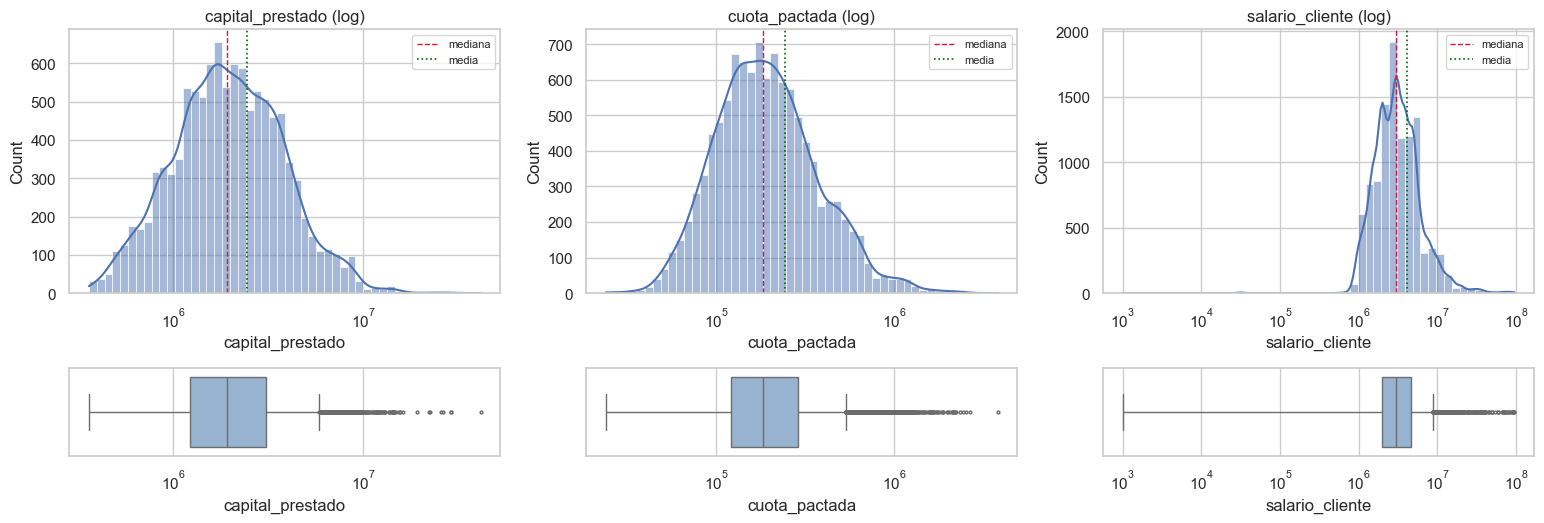

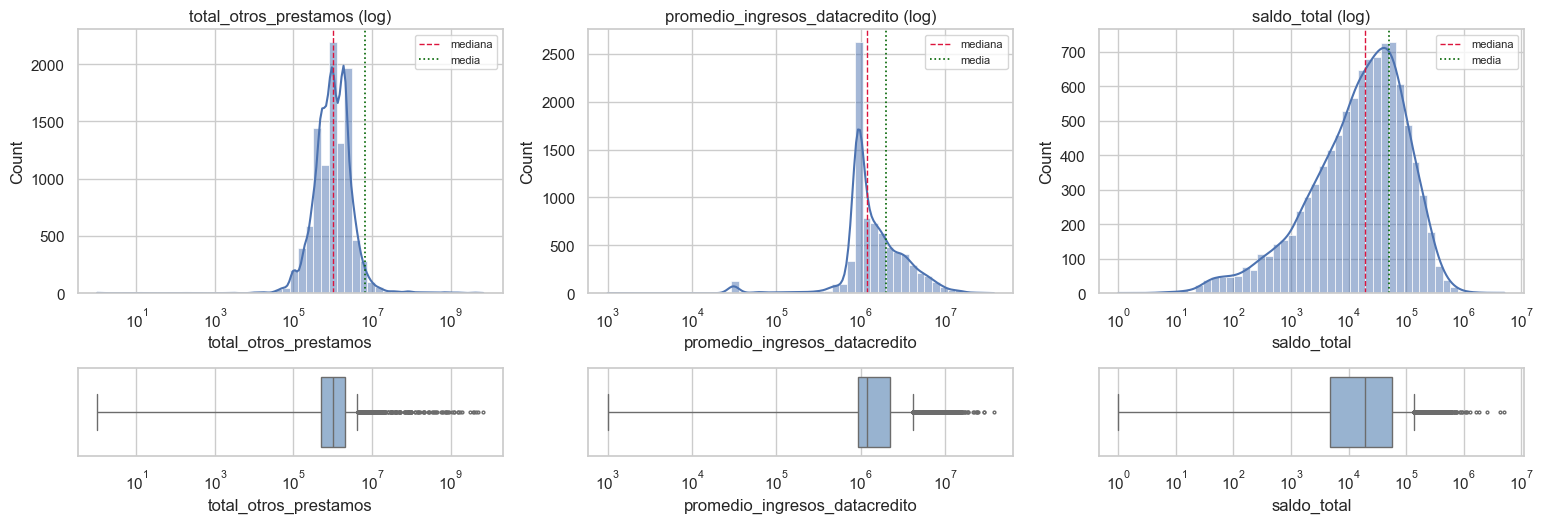

In [15]:
def plot_num(vars_, logx=False, cols_per_fig=3):
    for i in range(0, len(vars_), cols_per_fig):
        sub = vars_[i:i+cols_per_fig]
        fig, axes = plt.subplots(2, len(sub), figsize=(5.2*len(sub), 5.4),
                                 gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
        for j, c in enumerate(sub):
            x = d[c].dropna().astype(float)
            use_log = bool(logx and (x > 0).mean() > .9)
            xp = x[x > 0] if use_log else x
            if not use_log:                    # recorte visual a p1–p99 para legibilidad
                lo, hi = xp.quantile(.005), xp.quantile(.995); xp = xp[(xp >= lo) & (xp <= hi)]
            sns.histplot(xp, bins=50, kde=True, ax=axes[0, j], log_scale=use_log, color="#4C72B0")
            axes[0, j].axvline(xp.median(), color="crimson", ls="--", lw=1, label="mediana")
            axes[0, j].axvline(xp.mean(),   color="darkgreen", ls=":", lw=1.2, label="media")
            axes[0, j].set_title(c + (" (log)" if use_log else " (p0,5–p99,5)")); axes[0, j].legend(fontsize=8)
            sns.boxplot(x=xp, ax=axes[1, j], color="#8FB2D9", fliersize=2)
            if use_log: axes[1, j].set_xscale("log")
        plt.tight_layout(); plt.show()

plot_num(["capital_prestado", "cuota_pactada", "salario_cliente"], logx=True)
plot_num(["total_otros_prestamos", "promedio_ingresos_datacredito", "saldo_total"], logx=True)

Estas variables van **sin log**: tienen muchos ceros o un rango acotado.

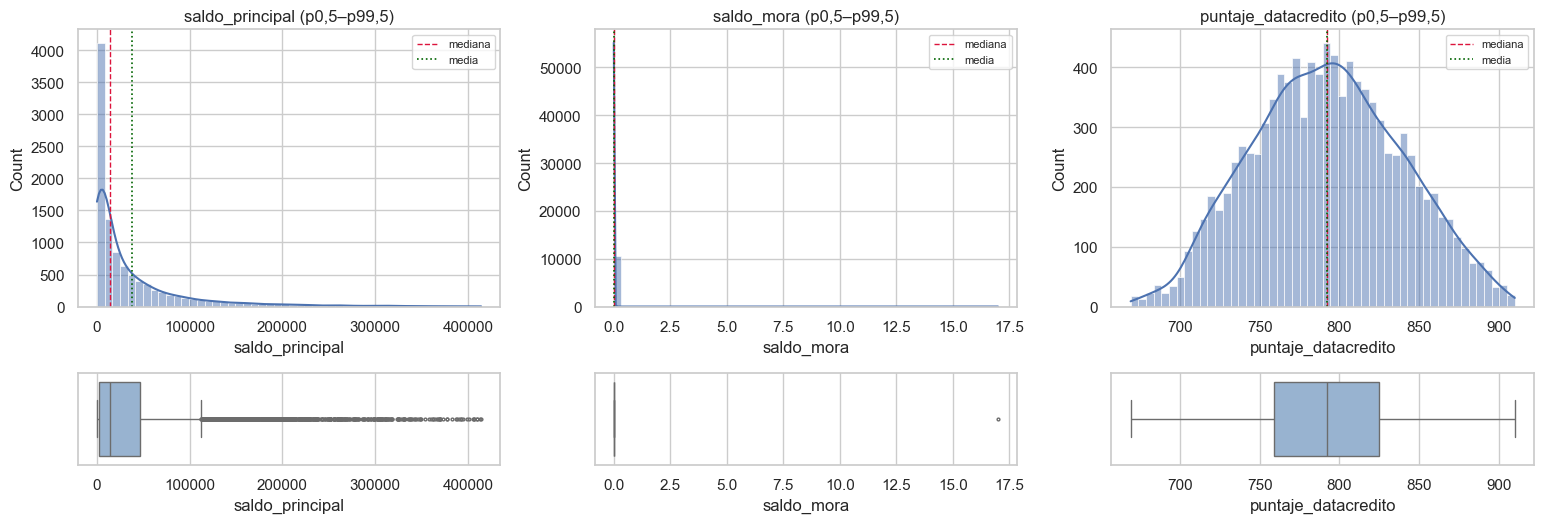

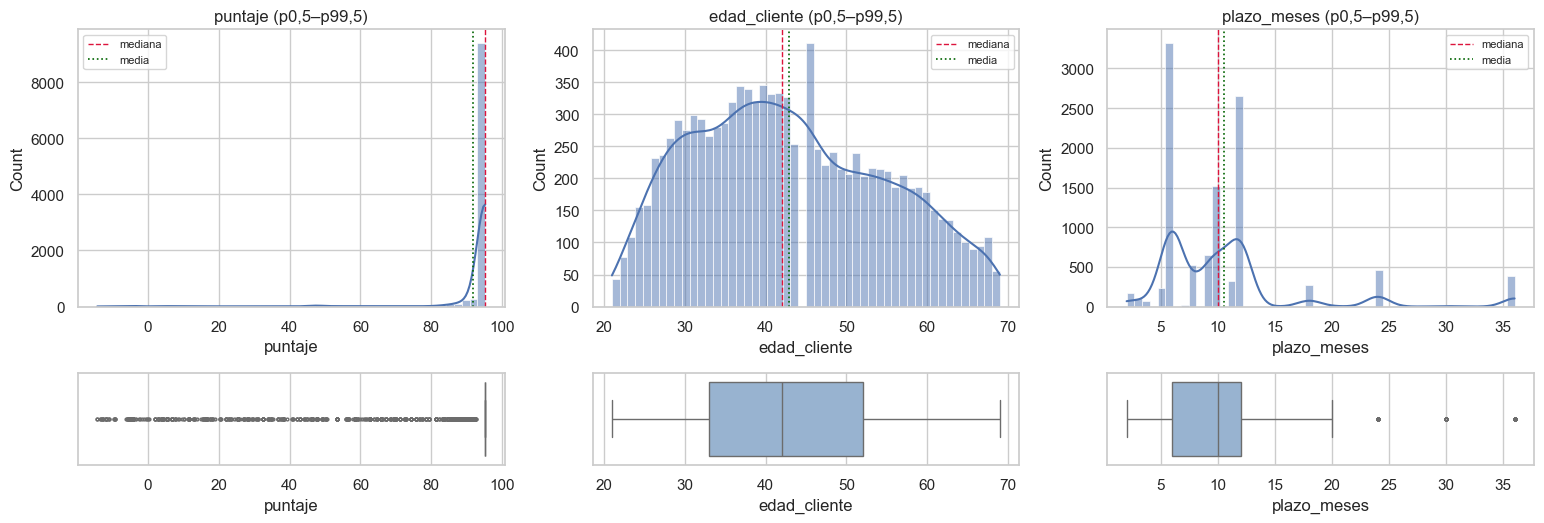

In [16]:
plot_num(["saldo_principal", "saldo_mora", "puntaje_datacredito"], logx=False)
plot_num(["puntaje", "edad_cliente", "plazo_meses"], logx=False)

Los conteos se grafican como **barras por valor** (son discretos), cortando a 25 valores.

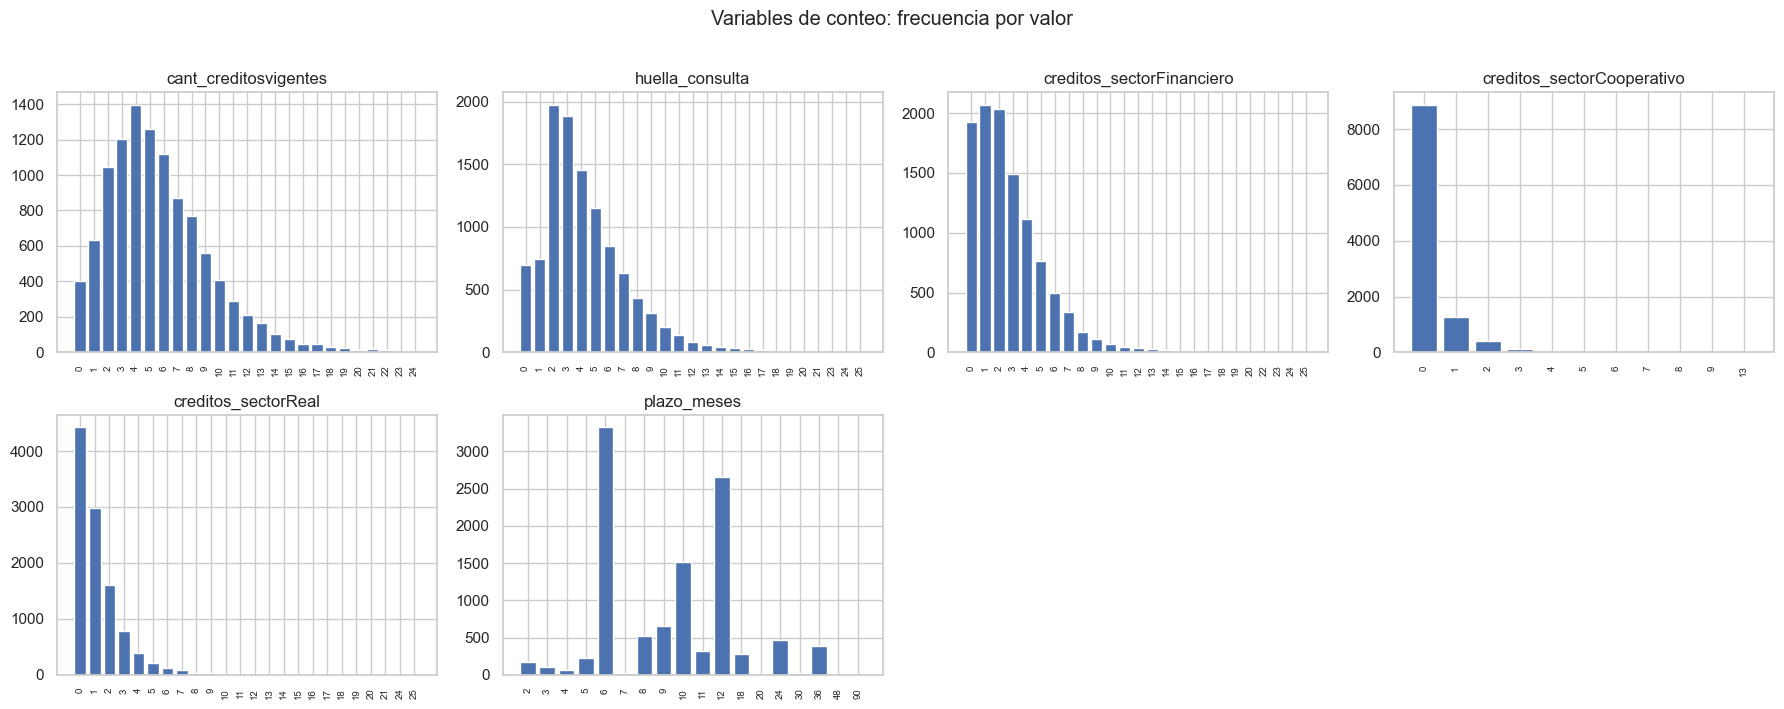

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), ["cant_creditosvigentes", "huella_consulta", "creditos_sectorFinanciero",
                                "creditos_sectorCooperativo", "creditos_sectorReal", "plazo_meses"]):
    vc = d[c].value_counts().sort_index()
    if len(vc) > 25: vc = vc[vc.index <= vc.index[24]]
    ax.bar(vc.index.astype(str), vc.values, color="#4C72B0"); ax.set_title(c)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
for ax in axes.ravel()[6:]: ax.axis("off")
plt.suptitle("Variables de conteo: frecuencia por valor", y=1.01); plt.tight_layout(); plt.show()

**Qué muestran los gráficos**
- `capital_prestado` y `cuota_pactada`: unimodales y casi simétricas en escala log.
- `salario_cliente`: cuerpo entre 10⁶ y 10⁷; tras anular los > 100 M quedan pocos puntos aislados (mínimo 1.000, máximo ≈ 96 M).
- `puntaje`: pico gigante en 95,23 y una masa pequeña por debajo (censurada, no natural).
- `puntaje_datacredito`: unimodal en ~790 con cola izquierda.
- `plazo_meses`: multimodal discreta (6 → 31 %, 12 → 25 %, 10 → 14 %): son plazos de producto; candidata a categórica ordenada.

## 3.3 Variables categóricas

Se incluyen los nulos en el conteo (`dropna=False`) para ver su peso real y el desbalance de cada categoría.


── tipo_credito ──


,n,%
tipo_credito,,
4,7747,71.9800
9,2876,26.7200
10,116,1.0800
6,21,0.2000
7,2,0.0200
68,1,0.0100



── tipo_laboral ──


,n,%
tipo_laboral,,
Empleado,6754,62.7500
Independiente,4009,37.2500



── tendencia_ingresos ──


,n,%
tendencia_ingresos,,
Creciente,5294,49.1900
NaN,2990,27.7800
Decreciente,1291,11.9900
Estable,1188,11.0400



── Pago_atiempo ──


,n,%
Pago_atiempo,,
1,10252,95.2500
0,511,4.7500


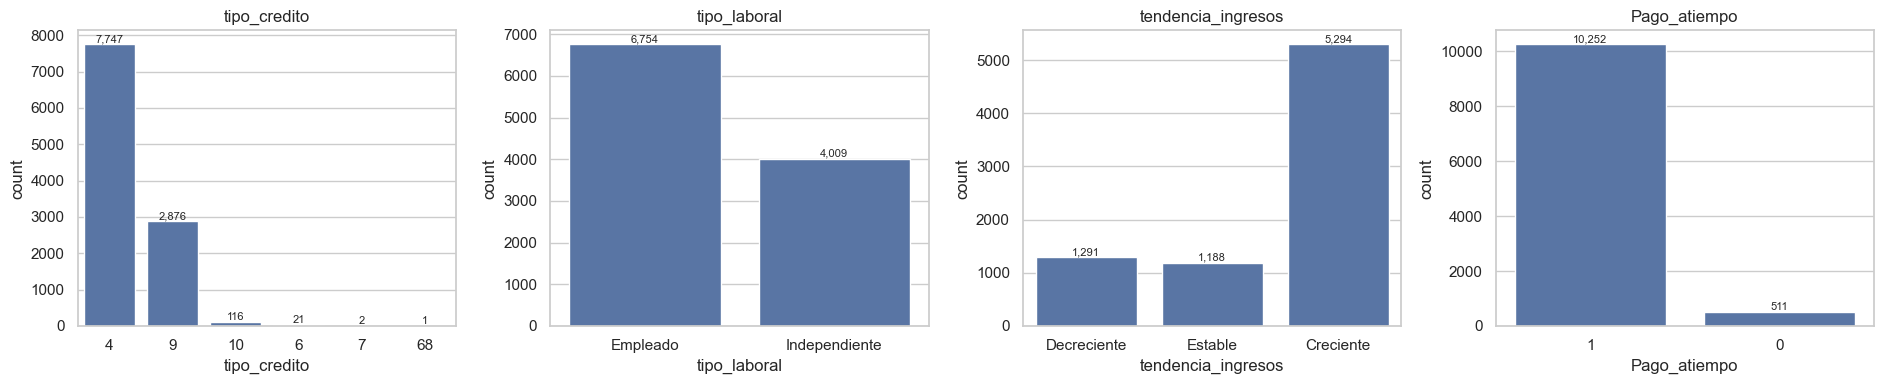

In [18]:
for c in CAT:
    vc = d[c].value_counts(dropna=False)
    out = pd.DataFrame({"n": vc, "%": (vc/len(d)*100).round(2)})
    print(f"\n── {c} ──")
    display(out)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, c in zip(axes, CAT):
    order = d[c].value_counts().index if c != "tendencia_ingresos" else ["Decreciente", "Estable", "Creciente"]
    sns.countplot(data=d, x=c, order=order, ax=ax, color="#4C72B0")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=8)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Interpretación**
- **Target muy desbalanceado:** 95,25 % pagó a tiempo vs 4,75 % (511 impagos). Usar *accuracy* sería una pésima idea en este contexto.  En su lugar, es preferible usar AUC-PR, KS o recall de la clase 0, y particiones **estratificadas**.
- **`tipo_credito`:** dominan los códigos 4 (72 %) y 9 (27 %); 6, 7 y 68 tienen 21, 2 y 1 registros → se agrupan como "Otros" (el 10, con 116, queda aparte).
- **`tipo_laboral`:** 63 % empleados, 37 % independientes.
- **`tendencia_ingresos`:** 27,8 % de nulos (2.990); entre los observados predomina "Creciente" (5.294), seguido de "Decreciente" (1.291) y "Estable" (1.188).

Resumen por segmento con la **mediana** (la media se distorsiona con outliers). `tipo_credito` se agrupa en 4, 9, 10 y Otros.

In [19]:
# Tablas pivote univariables / descriptivas por segmento
piv1 = pd.pivot_table(d, index="tipo_laboral", values=["capital_prestado","cuota_pactada","salario_cliente","edad_cliente"],
                      aggfunc=["count","median"], observed=True)
display(piv1)

d["tipo_credito_grp"] = d["tipo_credito"].astype(str).where(d["tipo_credito"].astype(str).isin(["4","9","10"]), "Otros")
piv2 = pd.pivot_table(d, index="tipo_credito_grp", values=["capital_prestado","plazo_meses","cuota_pactada"],
                      aggfunc=["count","median"], observed=True)
display(piv2)
display(d.groupby("tipo_laboral", observed=True)[TARGET].count().to_frame("n"))

count                                                      median                                           
              capital_prestado cuota_pactada edad_cliente salario_cliente capital_prestado cuota_pactada edad_cliente salario_cliente
tipo_laboral                                                                                                                         
Empleado                  6754          6754         6754            6754   1,951,365.0000  173,304.0000      40.0000  2,700,000.0000
Independiente             4009          4009         4009            4009   1,872,000.0000  206,818.0000      45.0000  3,800,000.0000

count                                     median                          
                 capital_prestado cuota_pactada plazo_meses capital_prestado cuota_pactada plazo_meses
tipo_credito_grp                                                                                      
10                            116           116         116   2,328,660.0000  189,528.5000     12.0000
4                            7747          7747        7747   1,929,896.4000  176,918.0000     10.0000
9                            2876          2876        2876   1,892,546.4000  204,382.0000     10.0000
Otros                          24            24          24   2,400,000.0000  154,785.0000     12.0000

,n
tipo_laboral,
Empleado,6754
Independiente,4009


- **Independientes vs empleados:** montos similares (≈ 1,9 M), pero los independientes declaran **más ingreso (3,8 M vs 2,7 M)**, son **mayores (45 vs 40 años)** y tienen **cuotas más altas (207 mil vs 173 mil)**.
- **Tipos de crédito:** el 4 y el 9 tienen montos y plazos casi idénticos (≈ 1,9 M; 10 meses), pero el 9 tiene cuota mayor (204 mil vs 177 mil). El 10 y "Otros" tienen montos algo mayores (2,3–2,4 M) y plazo de 12 meses, con muestras muy pequeñas (116 y 24).

## 3.4 Distribución temporal de los desembolsos

Se revisa el volumen por mes **antes** de interpretar el target: una distribución temporal irregular puede sesgar la validación.

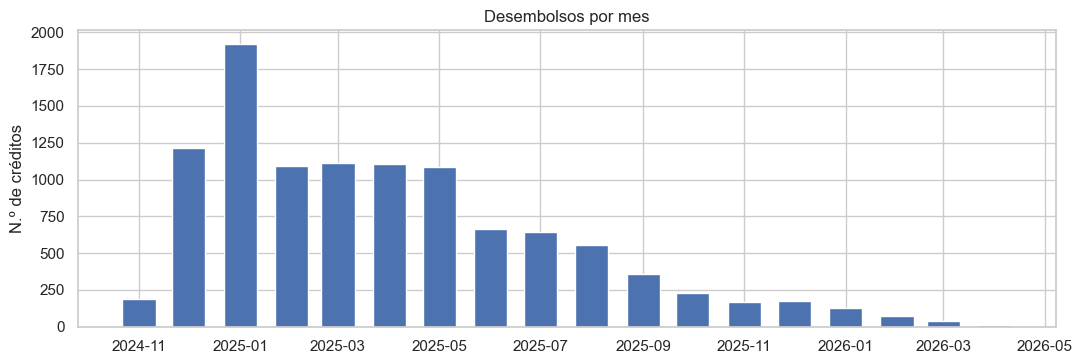

fecha_prestamo,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01
n,186.0000,"1,216.0000","1,917.0000","1,094.0000","1,115.0000","1,102.0000","1,083.0000",665.0000,644.0000,555.0000,361.0000,231.0000,166.0000,174.0000,127.0000,76.0000,40.0000,11.0000
tasa_pago,0.9301,0.9391,0.9551,0.9415,0.9489,0.9374,0.9566,0.9624,0.9689,0.9640,0.9806,0.9827,0.9578,0.9828,0.9449,0.9342,0.9500,0.9091


In [20]:
mes = d.set_index("fecha_prestamo").resample("MS").agg(n=(TARGET, "size"), tasa_pago=(TARGET, "mean"))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(mes.index, mes.n, width=20, color="#4C72B0"); ax.set_ylabel("N.º de créditos"); ax.set_title("Desembolsos por mes")
plt.tight_layout(); plt.show()
mes.T

**Observación importante:** el volumen cae de ~1.900 créditos/mes (enero 2025) a menos de 100/mes desde febrero 2026. No parece una caída real del negocio sino un **efecto de corte de muestra**: puede haber **sesgo de madurez** (los créditos recientes no han tenido tiempo de incumplir). Hay que definir la ventana de observación del target y validar con una **partición temporal**.

# 4. EDA bivariable (frente a `Pago_atiempo`)
## 4.1 Variables numéricas vs target
Se compara a pagadores (1) y no pagadores (0) con dos medidas:
- **Mann-Whitney U:** no paramétrico, robusto a colas pesadas y outliers.
- **AUC univariable** (probabilidad de que un pagador tenga un valor mayor que un no pagador): independiente de la escala. Se reporta `|AUC–0,5|×2` ("poder") para comparar fuerza sin importar el signo.

Con 10 mil filas casi todo es "significativo": importa más el **tamaño del efecto** que el p-valor.

In [21]:
def auc_uni(x, y):
    m = x.notna(); x, y = x[m].astype(float), y[m]
    r = stats.rankdata(x); n1, n0 = (y == 1).sum(), (y == 0).sum()
    return (r[y == 1].sum() - n1*(n1+1)/2) / (n1*n0)

filas = []
for c in CONT + DISC:
    x = d[c]; y = d[TARGET]
    a = auc_uni(x, y)
    u = stats.mannwhitneyu(x[y == 1].dropna().astype(float), x[y == 0].dropna().astype(float))
    filas.append({"variable": c, "mediana_paga": x[y == 1].median(), "mediana_no_paga": x[y == 0].median(),
                  "AUC": a, "poder (|AUC-.5|*2)": abs(a-.5)*2, "p_valor_MW": u.pvalue})
biv_num = pd.DataFrame(filas).set_index("variable").sort_values("poder (|AUC-.5|*2)", ascending=False)
with pd.option_context("display.float_format", lambda x: f"{x:,.4g}"):
    display(biv_num)

,mediana_paga,mediana_no_paga,AUC,poder (|AUC-.5|*2),p_valor_MW
variable,,,,,
puntaje,95.23,25.42,1,1,0
puntaje_datacredito,792,769,0.624,0.2479,7.033e-21
huella_consulta,4,5,0.4018,0.1963,3.907e-14
edad_cliente,42,38,0.5737,0.1473,1.796e-08
promedio_ingresos_datacredito,1.211e+06,1.053e+06,0.5726,0.1452,5.275e-06
capital_prestado,1.908e+06,2.268e+06,0.443,0.114,1.327e-05
creditos_sectorFinanciero,2,2,0.5406,0.08122,0.001682
total_otros_prestamos,1e+06,9e+05,0.5354,0.07079,0.006763
creditos_sectorReal,1,1,0.4765,0.04706,0.05876


`puntaje` se excluye del gráfico (su separación perfecta aplastaría la escala); se muestran las 9 variables con más señal, en escala log si el rango supera 20× la mediana.

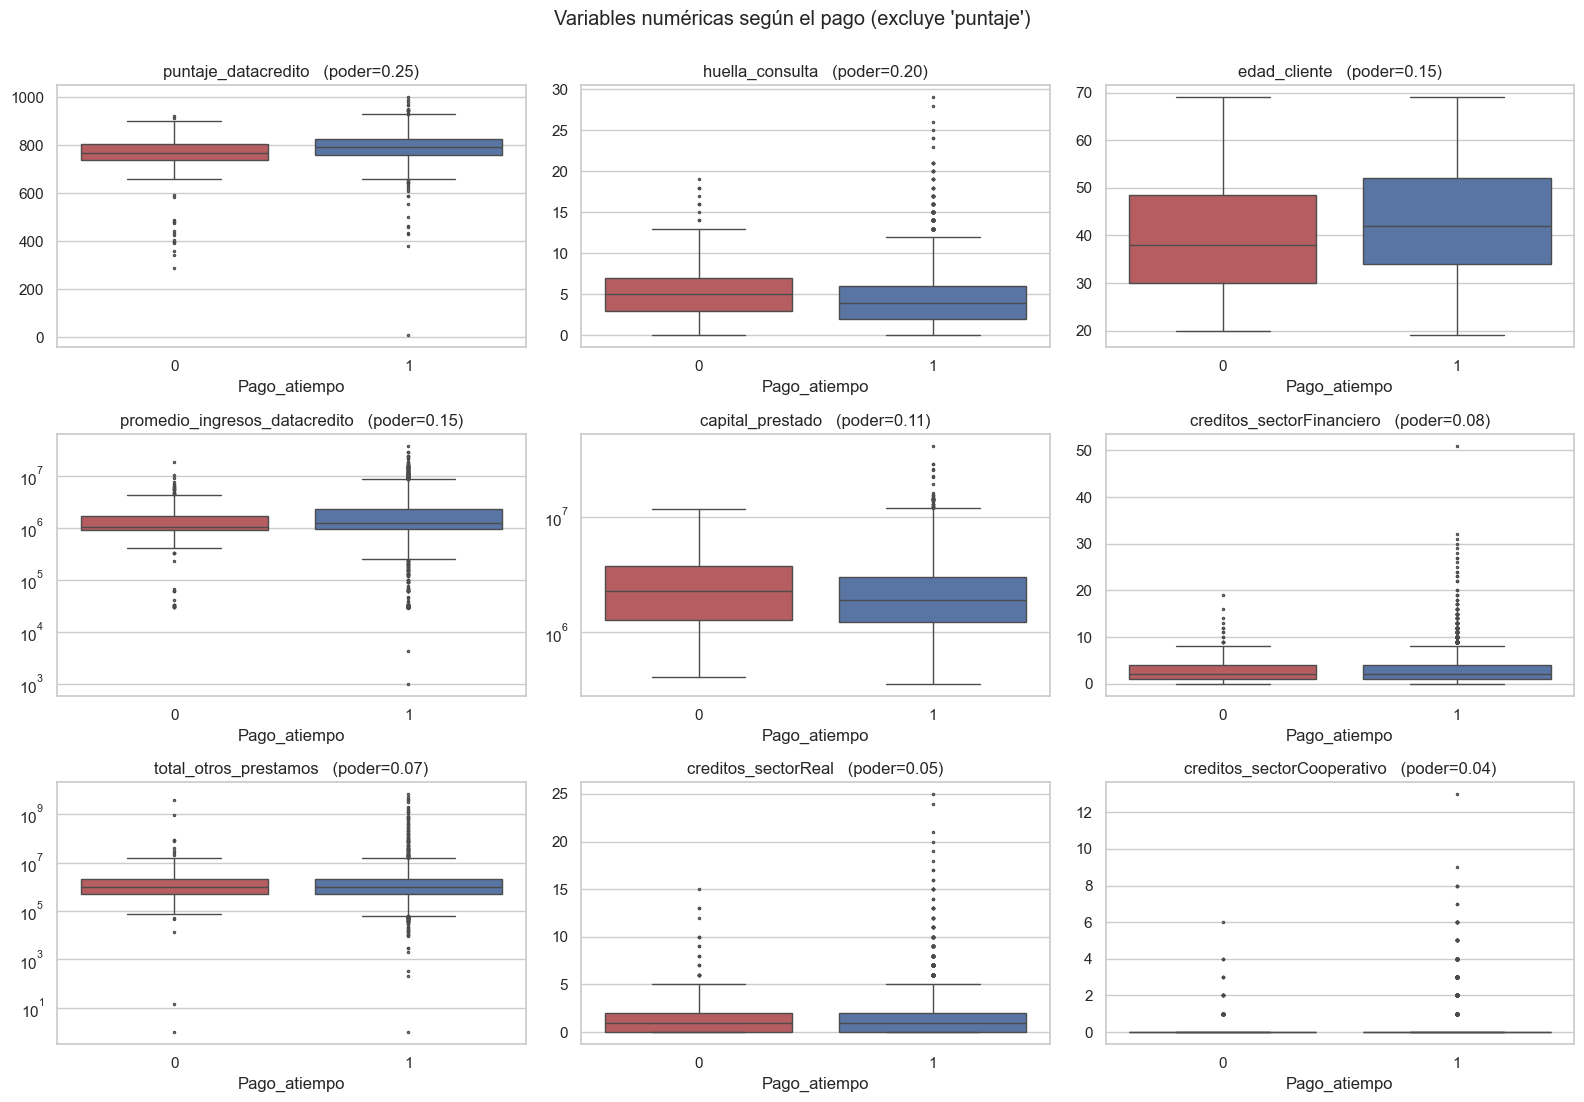

In [22]:
orden = biv_num.index.tolist()
sin_puntaje = [c for c in orden if c != "puntaje"][:9]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, c in zip(axes.ravel(), sin_puntaje):
    x = d[c].astype(float)
    plot_df = pd.DataFrame({"v": x, "Pago_atiempo": d[TARGET]}).dropna()
    if (plot_df.v > 0).mean() > .9 and plot_df.v.max()/max(plot_df.v.median(), 1) > 20:
        plot_df = plot_df[plot_df.v > 0]; ax.set_yscale("log")
    sns.boxplot(data=plot_df, x="Pago_atiempo", y="v", ax=ax, palette=["#C44E52", "#4C72B0"], fliersize=1.5)
    ax.set_title(f"{c}   (poder={biv_num.loc[c,'poder (|AUC-.5|*2)']:.2f})"); ax.set_ylabel("")
plt.suptitle("Variables numéricas según el pago (excluye 'puntaje')", y=1.0); plt.tight_layout(); plt.show()

**Lectura**
- Sin `puntaje`, **ninguna variable numérica discrimina fuerte** por sí sola: los mejores "poderes" van de 0,11 a 0,24. El riesgo es **difuso y multifactorial**.
- Ranking: **`puntaje_datacredito` (0,24)**, **`huella_consulta` (0,20)**, **`edad_cliente` (0,15)**, **`promedio_ingresos_datacredito` (0,145)** y **`capital_prestado` (0,11)**. Mejor score, mayor edad y mayor ingreso del buró → más pago; más consultas y mayor monto → menos pago.
- **`salario_cliente` (0,01) casi no discrimina**, mientras que el ingreso del buró sí: el ingreso declarado es **poco confiable**.
- **`plazo_meses`, `cuota_pactada`, `cant_creditosvigentes` y saldos** son débiles aquí (p ≈ 0,10 o mayor), pero el plazo tiene un **efecto umbral** (4.2).
- `saldo_mora` tiene p muy bajo con poder bajo: casi todo son ceros y los pocos > 0 pagan peor (poca cobertura, señal fuerte).

## 4.2 Tasa de pago por tramos
Los promedios ocultan relaciones **no lineales** (p. ej. el plazo solo afecta por encima de 12 meses); la tasa de pago por tramo las revela. Se usan **cuantiles** (mismo n por tramo) o cortes de negocio, e se imprime el `n` de cada tramo (una tasa sin n engaña: 38 % con n = 26).


puntaje_datacredito:
puntaje_datacredito  (0, 600]  (600, 700]  (700, 750]  (750, 800]  (800, 850]  (850, 1000]
%pago                 38.5000     90.8000     92.3000     95.5000     96.8000      97.1000
count                 26.0000    207.0000  1,937.0000  3,889.0000  3,239.0000   1,313.0000

huella_consulta:
huella_consulta  (-1, 0]     (0, 2]     (2, 4]     (4, 6]     (6, 8]  (8, 12]  (12, 100]
%pago            96.4000    97.2000    95.5000    94.4000    93.8000  91.3000    90.7000
count           700.0000 2,715.0000 3,340.0000 1,995.0000 1,062.0000 735.0000   216.0000

plazo_meses:
plazo_meses   (0, 5]     (5, 6]     (6, 9]    (9, 10]   (10, 12]  (12, 24]  (24, 100]
%pago        95.3000    95.2000    95.6000    95.0000    96.8000   93.2000    87.4000
count       579.0000 3,326.0000 1,198.0000 1,520.0000 2,982.0000  753.0000   405.0000

capital_prestado:
capital_prestado  (359999.999, 878880.0]  (878880.0, 1224831.0]  (1224831.0, 1560000.0]  (1560000.0, 1921920.0]  (1921920.0, 2400

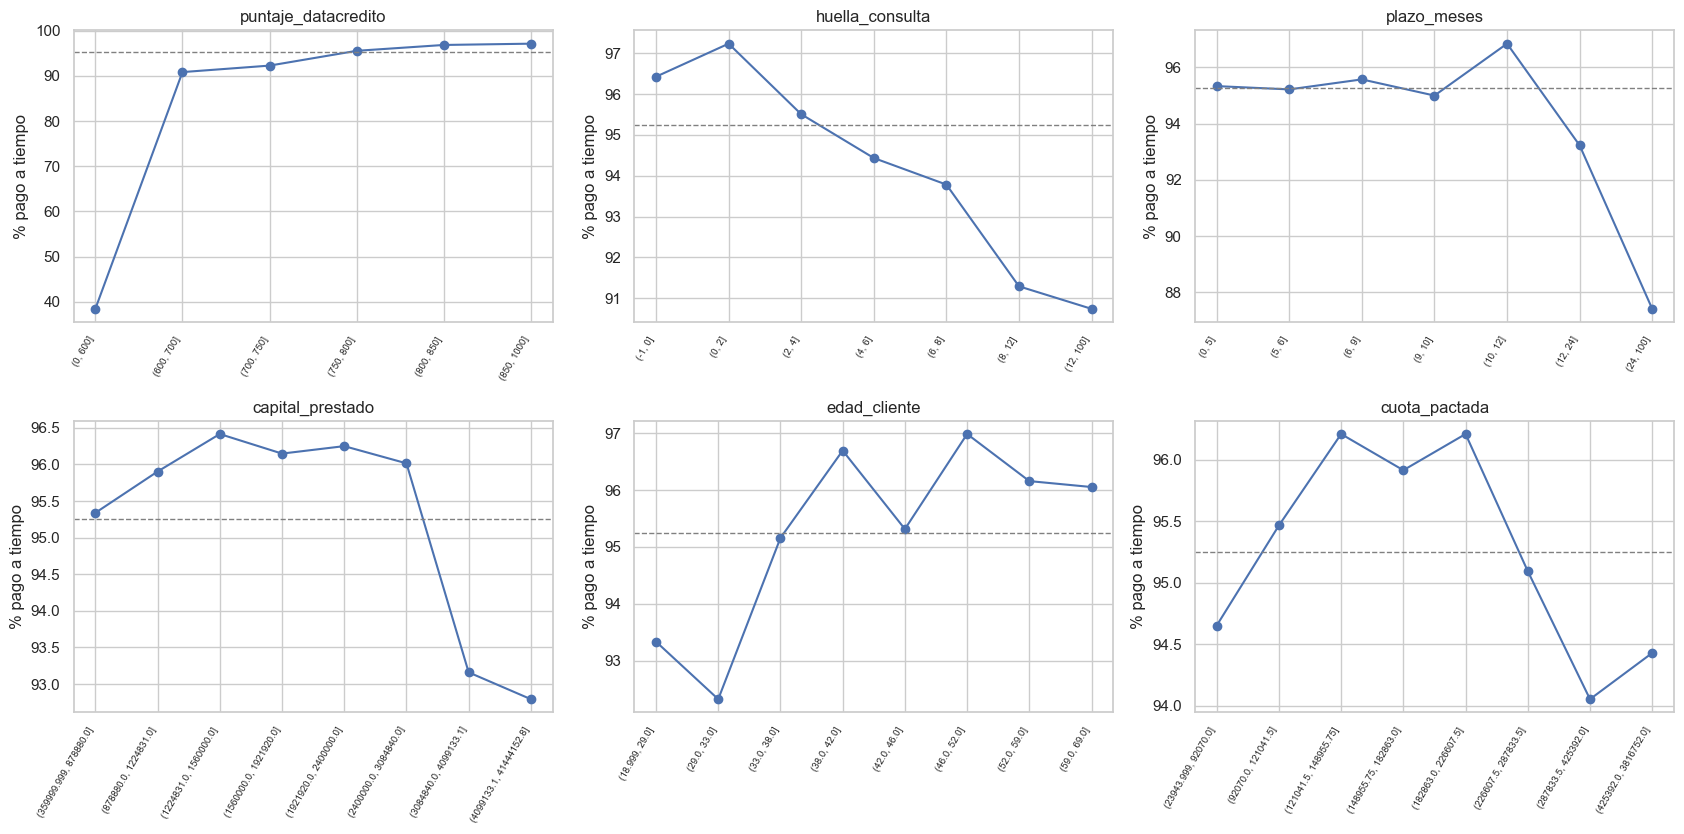

In [23]:
def tasa_por_tramos(var, q=8, ax=None, bins=None):
    s = d[var].astype(float)
    g = pd.cut(s, bins=bins) if bins is not None else pd.qcut(s, q, duplicates="drop")
    t = d.groupby(g, observed=True)[TARGET].agg(["mean", "count"])
    ax.plot(range(len(t)), t["mean"]*100, marker="o", color="#4C72B0")
    ax.axhline(d[TARGET].mean()*100, color="gray", ls="--", lw=1)
    ax.set_xticks(range(len(t))); ax.set_xticklabels([str(i) for i in t.index], rotation=60, ha="right", fontsize=7)
    ax.set_title(var); ax.set_ylabel("% pago a tiempo")
    print(f"\n{var}:"); print(t.assign(mean=t["mean"]*100).rename(columns={"mean": "%pago"}).round(1).T.to_string())
    return t

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, v in zip(axes.ravel(), ["puntaje_datacredito", "huella_consulta", "plazo_meses", "capital_prestado", "edad_cliente", "cuota_pactada"]):
    if v in ("huella_consulta", "plazo_meses"):
        b = [-1, 0, 2, 4, 6, 8, 12, 100] if v == "huella_consulta" else [0, 5, 6, 9, 10, 12, 24, 100]
        tasa_por_tramos(v, ax=ax, bins=b)
    elif v == "puntaje_datacredito":
        tasa_por_tramos(v, ax=ax, bins=[0, 600, 700, 750, 800, 850, 1000])
    else:
        tasa_por_tramos(v, q=8, ax=ax)
plt.tight_layout(); plt.show()

- **`puntaje_datacredito`:** creciente y monótona: 90,8 % (600–700) → 92,3 % → 95,5 % → 96,8 % → 97,1 % (> 850). El tramo ≤ 600 (26 casos) muestra 38,5 %, con muestra muy pequeña.
- **`huella_consulta`:** decreciente y monótona: 97,2 % con 1–2 consultas → 90,7 % con más de 12.
- **`plazo_meses`:** no es monótona; hasta 12 meses la tasa es 95–96,8 %, y baja a **93,2 % (13–24 meses)** y **87,4 % (> 24)**: efecto umbral.
- **`edad_cliente`:** los más jóvenes pagan peor (≈ 92–93 % hasta los 33 años vs 95–97 % desde los 38).
- **`capital_prestado`:** cae a ≈ 93 % por encima de ~3,1 M (vs ≈ 96 % en los tramos intermedios).
- **`cuota_pactada`:** casi plana (94–96 %).
- Relaciones interpretables y a veces no lineales: buen insumo para *binning* (WoE/IV) y árboles.

## 4.3 Variables categóricas vs target

- Los nulos de `tendencia_ingresos` se muestran como "Sin dato" (no se descartan): su tasa de pago es información.
- **Chi² + V de Cramér:** el chi² indica si hay asociación y V de Cramér su fuerza (0 a 1); es necesario porque con 10 mil filas el p-valor siempre sale pequeño.

,tasa_pago,n,variable
tipo_credito_txt,,,
10,97.4100,116,tipo_credito_txt
4,95.3100,7747,tipo_credito_txt
9,95.2700,2876,tipo_credito_txt
Otros,62.5000,24,tipo_credito_txt


,tasa_pago,n,variable
tipo_laboral,,,
Empleado,95.7100,6754,tipo_laboral
Independiente,94.4900,4009,tipo_laboral


,tasa_pago,n,variable
tendencia_ingresos_txt,,,
Creciente,96.0900,5294,tendencia_ingresos_txt
Decreciente,93.7300,1291,tendencia_ingresos_txt
Estable,95.3700,1188,tendencia_ingresos_txt
Sin dato,94.3800,2990,tendencia_ingresos_txt


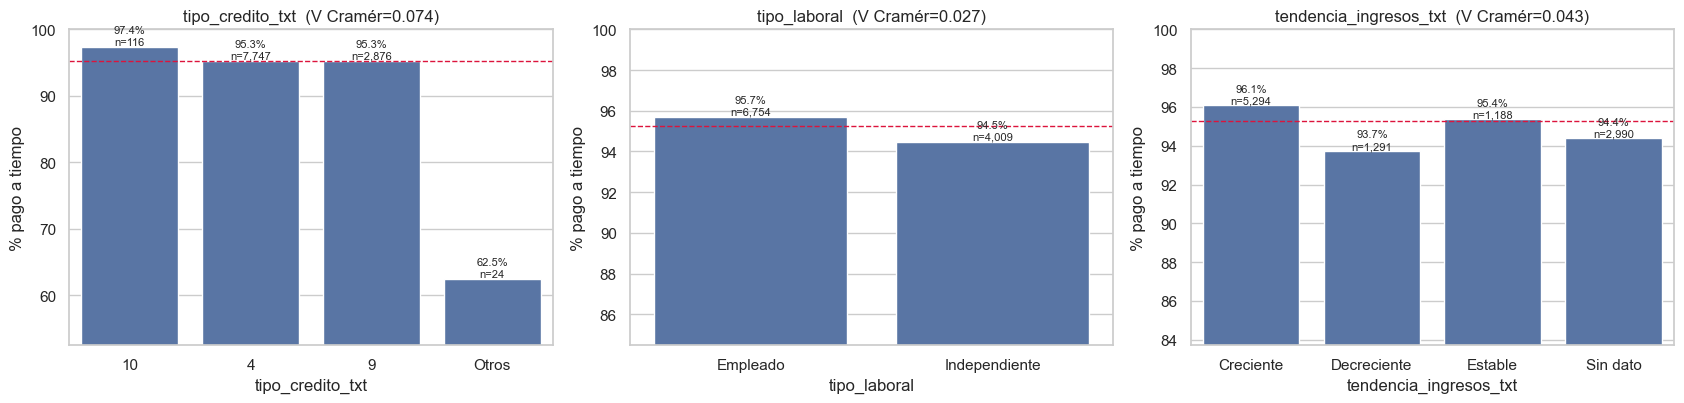

,chi2,p_valor,V_Cramer
variable,,,
tipo_credito_txt,58.1954,0.0000,0.0735
tipo_laboral,7.9968,0.0047,0.0273
tendencia_ingresos_txt,19.9181,0.0002,0.0430


In [24]:
d["tendencia_ingresos_txt"] = d["tendencia_ingresos"].astype(object).where(d["tendencia_ingresos"].notna(), "Sin dato")
d["tipo_credito_txt"] = d["tipo_credito_grp"]
res = []
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c in zip(axes, ["tipo_credito_txt", "tipo_laboral", "tendencia_ingresos_txt"]):
    t = d.groupby(c, observed=True)[TARGET].agg(tasa_pago="mean", n="count")
    t["tasa_pago"] *= 100
    ct = pd.crosstab(d[c], d[TARGET]); chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
    res.append({"variable": c, "chi2": chi2, "p_valor": p, "V_Cramer": v})
    display(t.round(2).assign(variable=c))
    sns.barplot(x=t.index.astype(str), y=t["tasa_pago"], ax=ax, color="#4C72B0")
    ax.axhline(d[TARGET].mean()*100, color="crimson", ls="--", lw=1)
    ax.set_ylim(max(0, t.tasa_pago.min()-10), 100); ax.set_title(f"{c}  (V Cramér={v:.3f})"); ax.set_ylabel("% pago a tiempo")
    for p_, (idx, r) in zip(ax.patches, t.iterrows()):
        ax.annotate(f"{r.tasa_pago:.1f}%\nn={int(r.n):,}", (p_.get_x()+p_.get_width()/2, p_.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(res).set_index("variable")

Las tres asociaciones son significativas (p < 0,01) pero **pequeñas** (V de Cramér ≤ 0,07).
- **`tipo_laboral`:** empleados 95,7 % vs independientes 94,5 %.
- **`tendencia_ingresos`:** Creciente (96,1 %) > Estable (95,4 %) > Decreciente (93,7 %); "Sin dato" (94,4 %) queda entre Estable y Decreciente.
- **`tipo_credito`:** 4 y 9 casi idénticos (95,3 %); el 10 es algo mejor (97,4 %, n = 116) y "Otros" mucho peor (62,5 %, n = 24, empujado por el código 6: 57 % con n = 21). La significancia viene casi toda de "Otros": **no sobre-interpretar** grupos tan pequeños.
- Ninguna categórica tiene gran poder por sí sola.

## 4.4 ⚠ Análisis de la variable `puntaje`: fuga de información (data leakage)
`puntaje` tiene una correlación de **0,92** con el target. Se investiga su naturaleza.

Tres pruebas independientes sostienen que `puntaje` es una **fuga de información**:
1. **Distribución por clase:** si los rangos no se solapan, la variable "conoce" el resultado.
2. **Umbral y AUC:** un corte en ~63 clasifica al 100 %; un AUC de 1,00 es imposible en riesgo real.
3. **Valores repetidos entre los impagos** (47,6139 = la mitad de 95,2278): el puntaje se calcula **a partir del desenlace**.

                   count    mean     std      min     25%     50%     75%     max
Pago_atiempo                                                                     
0               511.0000 23.0910 26.0710 -38.0100 -3.5920 25.4190 47.6140 62.6680
1            10,252.0000 94.5630  2.8740  63.8100 95.2280 95.2280 95.2280 95.2280

Solapamiento: máx(puntaje | no pagó) = 62.668  | mín(puntaje | pagó) = 63.81

Umbral ≈ 63:  puntaje < 63 → tasa de pago 0.0%  (n=511)
                  puntaje ≥ 63 → tasa de pago 100.0%  (n=10252)
AUC univariable de 'puntaje': 1.0


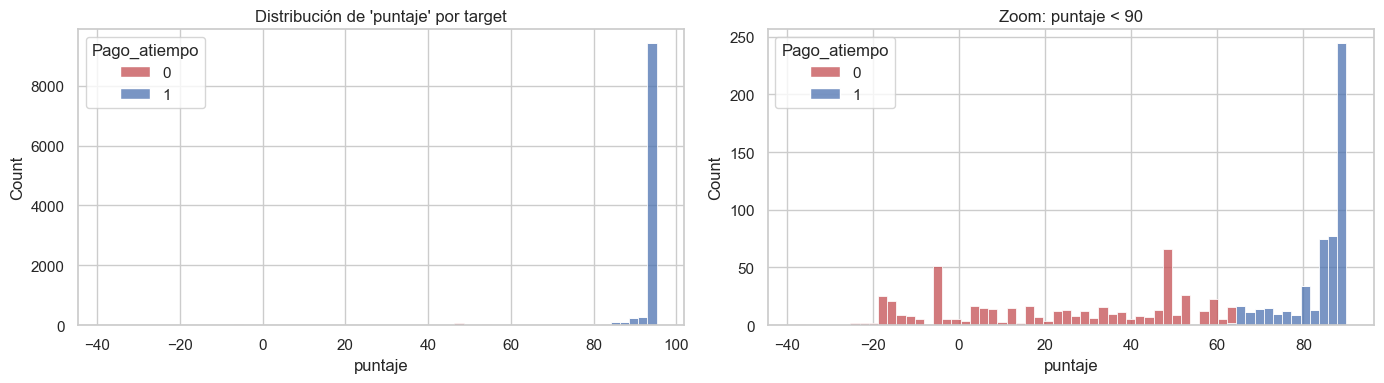


Valores más frecuentes de 'puntaje' entre los NO pagadores:
puntaje
47.6140     59
58.5980     17
-18.4710    16
-5.1030     16
62.6680     12
-4.7280     11


In [25]:
print(d.groupby(TARGET)["puntaje"].describe().round(3))
print("\nSolapamiento: máx(puntaje | no pagó) =", round(d.loc[d[TARGET]==0,"puntaje"].max(), 3),
      " | mín(puntaje | pagó) =", round(d.loc[d[TARGET]==1,"puntaje"].min(), 3))

umbral = 63
print(f"\nUmbral ≈ {umbral}:  puntaje < {umbral} → tasa de pago {d.loc[d.puntaje<umbral,TARGET].mean()*100:.1f}%  (n={int((d.puntaje<umbral).sum())})")
print(f"                  puntaje ≥ {umbral} → tasa de pago {d.loc[d.puntaje>=umbral,TARGET].mean()*100:.1f}%  (n={int((d.puntaje>=umbral).sum())})")
print("AUC univariable de 'puntaje':", round(auc_uni(d.puntaje, d[TARGET]), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=d, x="puntaje", hue=TARGET, bins=60, multiple="stack", palette=["#C44E52", "#4C72B0"], ax=axes[0])
axes[0].set_title("Distribución de 'puntaje' por target")
sns.histplot(data=d[d.puntaje < 90], x="puntaje", hue=TARGET, bins=60, multiple="stack", palette=["#C44E52", "#4C72B0"], ax=axes[1])
axes[1].set_title("Zoom: puntaje < 90")
plt.tight_layout(); plt.show()

print("\nValores más frecuentes de 'puntaje' entre los NO pagadores:")
print(d.loc[d[TARGET]==0, "puntaje"].round(3).value_counts().head(6).to_string())

**Conclusión: `puntaje` NO debe usarse como predictor.**
1. **Separación perfecta:** todos los créditos con `puntaje` < ~63 son impagos y todos los de ≥ ~64 son pagos (máximo de los impagos 62,7; mínimo de los pagos 63,8). AUC = 1,00.
2. **Valores repetidos:** 47,6139 es exactamente la mitad de 95,2278; el puntaje parece partir de un máximo (95,2278) para quien pagó a tiempo y reducirse según la mora. Es una **consecuencia** del target, no una causa.
3. Los pagadores con puntaje < 90 (533 casos) sugieren pagos con alguna demora menor.

**Acción:** eliminarla de la base de trabajo (celda siguiente) y **confirmar con negocio** cuándo se calcula. Si estuviera disponible *antes* del desembolso habría que justificarlo, pero este patrón apunta a un *post-outcome score*. Aun así, podría servir como definición alternativa del target (severidad del retraso).

### Eliminación de `puntaje`
Se retira de `d` y de `CONT`, de modo que **ninguna sección posterior** (correlaciones, pairplot, derivados, exportación) la use por accidente. Se conserva en `raw` por si negocio confirma que existe antes del desembolso. Las secciones 3 y 4.1–4.3 la muestran porque son anteriores a este diagnóstico.

In [26]:
d = d.drop(columns=["puntaje"])
CONT.remove("puntaje")
print("'puntaje' eliminada. Columnas restantes:", d.shape[1], "| 'puntaje' en d:", "puntaje" in d.columns)

'puntaje' eliminada. Columnas restantes: 28 | 'puntaje' en d: False


## 4.5 Los nulos del buró y el target

Se comprueba que los indicadores de ausencia y de mora llevan señal antes de conservarlos. `tiene_mora` marca `saldo_mora > 0`; los 156 nulos quedan en `False` y `sin_saldos_buro` los identifica.

In [27]:
for c in ["sin_historial_ingresos_buro", "sin_score_buro", "sin_saldos_buro"]:
    t = d.groupby(c)[TARGET].agg(tasa_pago="mean", n="count"); t["tasa_pago"] *= 100
    print(f"\n{c}"); display(t.round(2))

# mora
d["tiene_mora"] = (d["saldo_mora"] > 0)
display(d.groupby("tiene_mora")[TARGET].agg(tasa_pago="mean", n="count").assign(tasa_pago=lambda x: x.tasa_pago*100).round(2))


sin_historial_ingresos_buro


,tasa_pago,n
sin_historial_ingresos_buro,,
False,95.5900,7773
True,94.3800,2990



sin_score_buro


,tasa_pago,n
sin_score_buro,,
False,95.2900,10611
True,92.7600,152



sin_saldos_buro


,tasa_pago,n
sin_saldos_buro,,
False,95.3500,10358
True,92.8400,405


,tasa_pago,n
tiene_mora,,
False,95.4100,10708
True,63.6400,55


- **Mora vigente** (`saldo_mora > 0`) es la señal binaria más fuerte (≈ 64 % vs ≈ 95 % de pago), pero cubre solo 55 créditos.
- **Sin historial de ingresos** o **sin score** se asocian a menor pago (1–3 puntos porcentuales): se justifica conservar los indicadores.

## 4.6 Evolución temporal del target

Se agrega por **trimestre** (no por mes) para tener n suficiente por punto y detectar deriva temporal.

fecha_prestamo,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
tasa_pago,93.7900,94.9800,95.0500,96.9900,97.5500,94.2400,90.9100
n,"1,402.0000","4,126.0000","2,850.0000","1,560.0000",571.0000,243.0000,11.0000


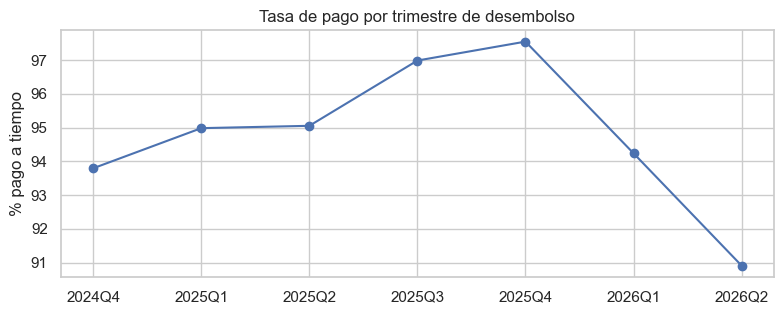

In [28]:
t = d.groupby(d.fecha_prestamo.dt.to_period("Q"), observed=True)[TARGET].agg(tasa_pago="mean", n="count")
t["tasa_pago"] *= 100
display(t.round(2).T)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(t.index.astype(str), t.tasa_pago, marker="o"); ax.set_ylabel("% pago a tiempo"); ax.set_title("Tasa de pago por trimestre de desembolso")
plt.tight_layout(); plt.show()

La tasa de pago **sube de ~94 % (4T-2024) a ~97,5 % (4T-2025)** y baja en 2026 (muestras pequeñas: 243 y 11 casos). Puede reflejar mejor originación **o** el efecto de madurez de 3.4 (los créditos recientes aún no han podido incumplir). Se confirma la necesidad de validación temporal.

# 5. EDA multivariable
## 5.1 Matriz de correlación (Spearman)
Se usa **Spearman** (rangos) por las colas pesadas y las relaciones monótonas. `puntaje` ya no está en la base (eliminado en 4.4). Se muestra el triángulo inferior, las correlaciones con el target y los 12 pares más altos (para detectar **multicolinealidad**).

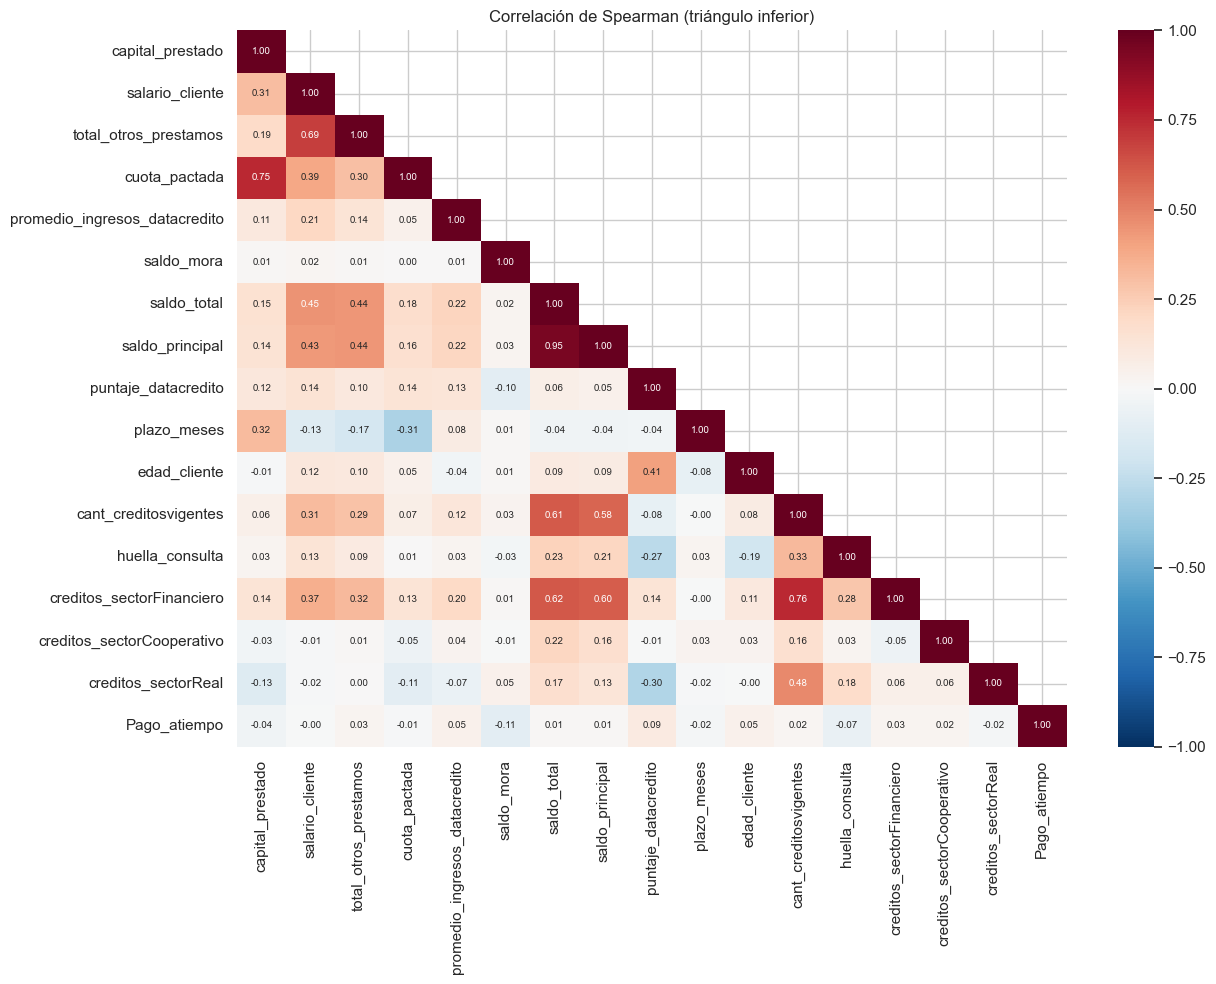

Correlación de Spearman de cada variable con el target (ordenada):


,rho
saldo_mora,-0.1080
huella_consulta,-0.0730
capital_prestado,-0.0420
creditos_sectorReal,-0.0180
plazo_meses,-0.0160
cuota_pactada,-0.0150
salario_cliente,-0.0040
saldo_principal,0.0090
saldo_total,0.0150
cant_creditosvigentes,0.0160


Top 12 pares más correlacionados:


,var_1,var_2,rho
81,saldo_total,saldo_principal,0.9463
122,cant_creditosvigentes,creditos_sectorFinanciero,0.7552
2,capital_prestado,cuota_pactada,0.7507
16,salario_cliente,total_otros_prestamos,0.6940
87,saldo_total,creditos_sectorFinanciero,0.6215
85,saldo_total,cant_creditosvigentes,0.6136
96,saldo_principal,creditos_sectorFinanciero,0.6045
94,saldo_principal,cant_creditosvigentes,0.5789
124,cant_creditosvigentes,creditos_sectorReal,0.4781
20,salario_cliente,saldo_total,0.4471


In [29]:
num_for_corr = CONT + DISC + [TARGET]   # puntaje ya fue eliminado en 4.4
corr = d[num_for_corr].astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
ax.set_title("Correlación de Spearman (triángulo inferior)")
plt.tight_layout(); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares["abs"] = pares.rho.abs()
print("Correlación de Spearman de cada variable con el target (ordenada):")
display(corr[TARGET].drop(TARGET).sort_values().round(3).to_frame("rho"))
print("Top 12 pares más correlacionados:")
display(pares.sort_values("abs", ascending=False).head(12).drop(columns="abs"))

**Interpretación**
- **Predictores muy correlacionados:** `saldo_total ↔ saldo_principal` (0,95), `cant_creditosvigentes ↔ creditos_sectorFinanciero` (0,76), `capital_prestado ↔ cuota_pactada` (0,75) y `salario_cliente ↔ total_otros_prestamos` (0,69). Para modelos lineales conviene retirar o combinar; para árboles no es grave.
- Los saldos crecen con el endeudamiento (`saldo_total ↔ cant_creditosvigentes` ≈ 0,61).
- **Con el target todas las correlaciones son bajas (|ρ| ≤ 0,11):** `saldo_mora` (–0,11), `puntaje_datacredito` (+0,09), `huella_consulta` (–0,07), `edad_cliente` (+0,05) y `promedio_ingresos_datacredito` (+0,05). No hay variable dominante (salvo la fuga ya eliminada).

## 5.2 Pairplot de variables clave
Muestra de visualización: todos los impagos (511) + 1.200 pagos, porque con la proporción real (4,7 %) los puntos rojos serían invisibles (esto **distorsiona la proporción**; solo sirve para ver patrones). Capital y cuota van en log10 y se eligen 6 variables para que sea legible.

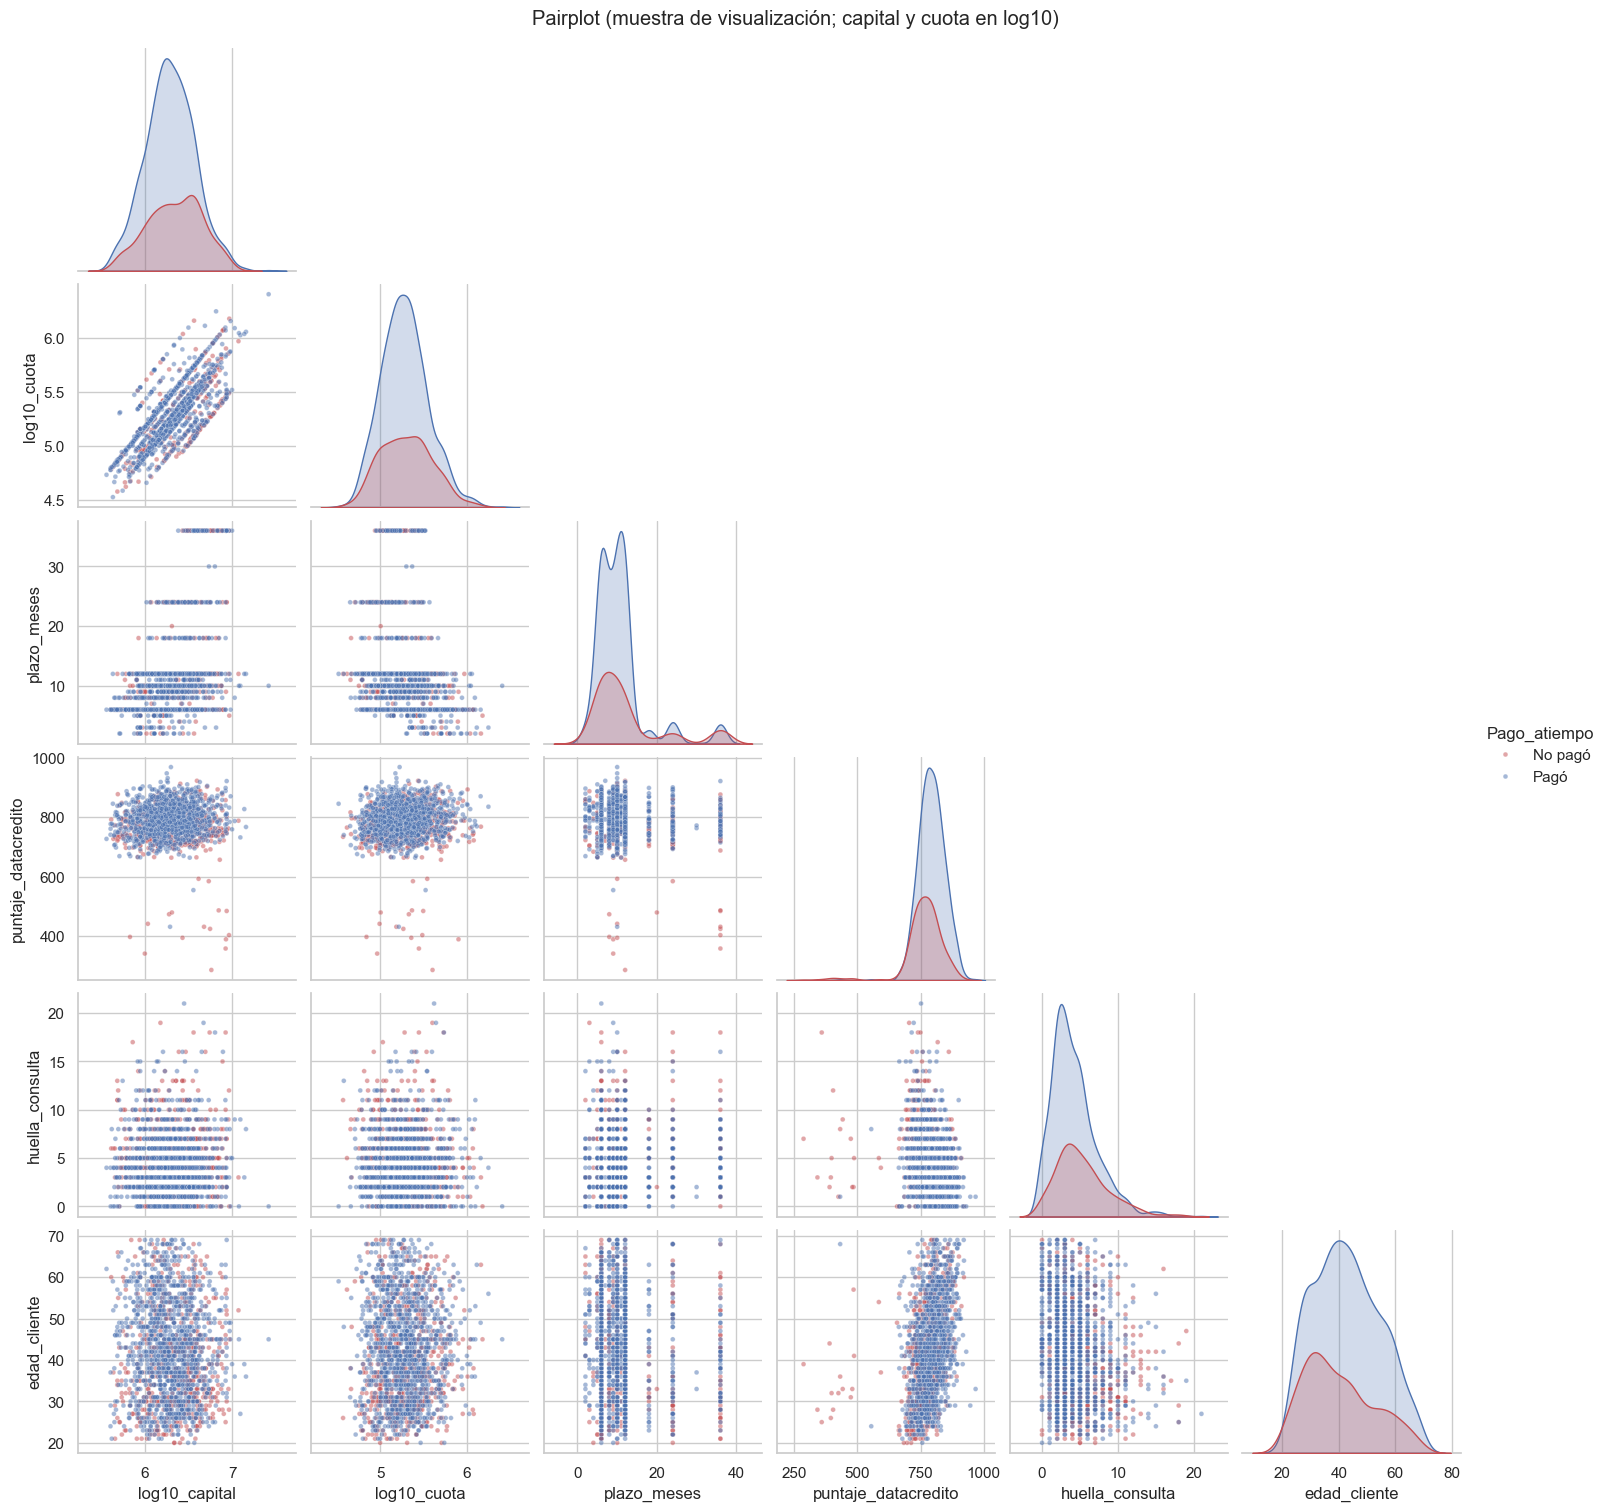

In [30]:
vis = pd.concat([d[d[TARGET] == 0], d[d[TARGET] == 1].sample(1200, random_state=SEED)])
pp = vis[["capital_prestado", "cuota_pactada", "plazo_meses", "puntaje_datacredito", "huella_consulta", "edad_cliente", TARGET]].copy()
pp["capital_prestado"] = np.log10(pp.capital_prestado); pp["cuota_pactada"] = np.log10(pp.cuota_pactada)
pp = pp.rename(columns={"capital_prestado": "log10_capital", "cuota_pactada": "log10_cuota"})
pp[TARGET] = pp[TARGET].map({0: "No pagó", 1: "Pagó"})
g = sns.pairplot(pp, hue=TARGET, palette={"No pagó": "#C44E52", "Pagó": "#4C72B0"}, corner=True,
                 plot_kws={"s": 12, "alpha": .5}, diag_kind="kde")
g.fig.suptitle("Pairplot (muestra de visualización; capital y cuota en log10)", y=1.01); plt.show()

- `log10_capital` vs `log10_cuota`: **bandas lineales paralelas** (una por plazo); la cuota queda determinada por monto y plazo, así que conviene usar **razones** (cuota/ingreso).
- `puntaje_datacredito` vs `edad_cliente`: asociación positiva (los mayores tienen mejor score).
- Los no pagadores (rojo) **no forman un cluster** en la mayoría de pares. Excepciones: un pequeño grupo con score < 600, casi todo rojo, y mayor densidad de impagos en edades jóvenes (~28–38) y capitales altos.

## 5.3 Gráficos con `hue` (variable categórica de color)

Se usa `hue` para ver si el patrón se mantiene **dentro** de cada grupo: (a) capital vs cuota por tipo laboral, (b) score del buró por tendencia y pago, (c) tasa de pago por huella según plazo.

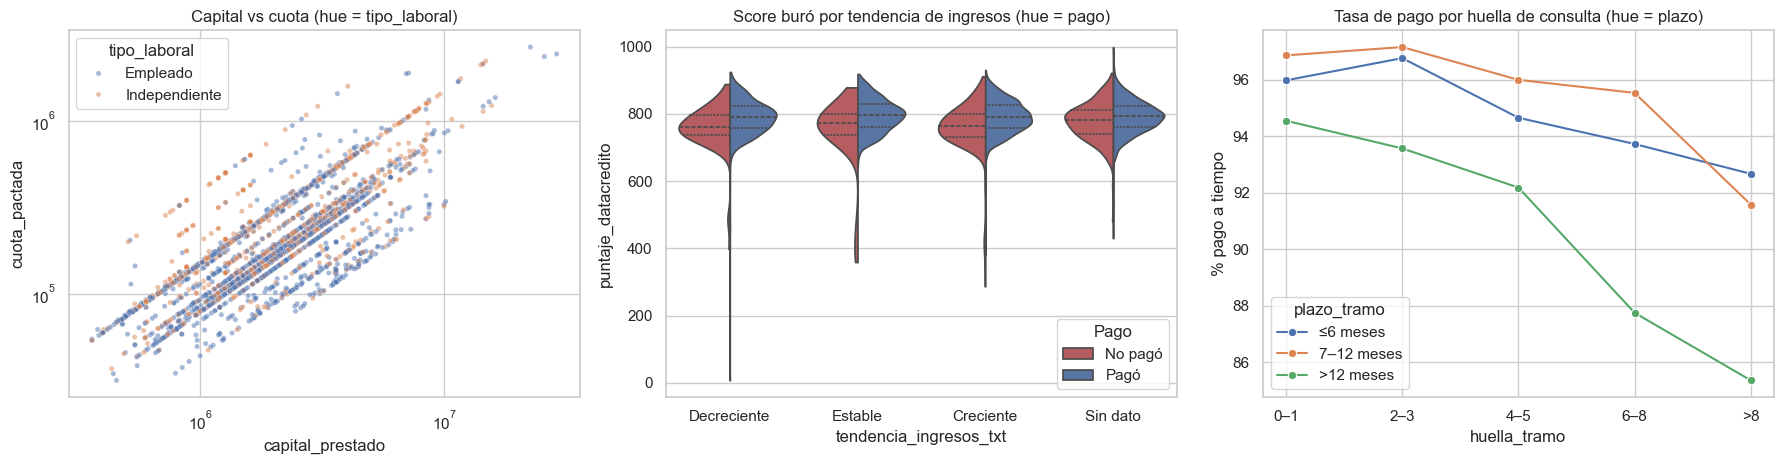

Mediana de puntaje_datacredito por tendencia y pago:


median            count      
Pago                    No pagó     Pagó No pagó  Pagó
tendencia_ingresos_txt                                
Creciente              763.0000 791.0000     207  5086
Decreciente            762.0000 791.0000      81  1210
Estable                772.0000 797.0000      55  1133
Sin dato               781.0000 793.0000     157  2682

Mediana capital y cuota por tipo laboral:


,capital_prestado,cuota_pactada,plazo_meses,salario_cliente,edad_cliente
tipo_laboral,,,,,
Empleado,"1,951,365.0000","173,304.0000",10.0000,"2,700,000.0000",40.0000
Independiente,"1,872,000.0000","206,818.0000",8.0000,"3,800,000.0000",45.0000


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
# (a) capital vs cuota coloreado por tipo laboral
s = d.sample(3000, random_state=SEED)
sns.scatterplot(data=s, x="capital_prestado", y="cuota_pactada", hue="tipo_laboral", alpha=.5, s=14, ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("Capital vs cuota (hue = tipo_laboral)")
# (b) score buró por tendencia de ingresos y target
dd = d.dropna(subset=["puntaje_datacredito"]).copy(); dd["Pago"] = dd[TARGET].map({0: "No pagó", 1: "Pagó"})
sns.violinplot(data=dd, x="tendencia_ingresos_txt", y="puntaje_datacredito", hue="Pago", split=True, cut=0,
               order=["Decreciente", "Estable", "Creciente", "Sin dato"], hue_order=["No pagó", "Pagó"],
               palette={"No pagó": "#C44E52", "Pagó": "#4C72B0"}, inner="quartile", ax=axes[1])
axes[1].set_title("Score buró por tendencia de ingresos (hue = pago)")
# (c) tasa de pago según huella de consulta, una línea por tramo de plazo (hue = plazo)
tmp = d.copy()
tmp["plazo_tramo"] = pd.cut(tmp.plazo_meses, [0, 6, 12, 100], labels=["≤6 meses", "7–12 meses", ">12 meses"])
tmp["huella_tramo"] = pd.cut(tmp.huella_consulta, [-1, 1, 3, 5, 8, 100], labels=["0–1", "2–3", "4–5", "6–8", ">8"])
lin = tmp.groupby(["plazo_tramo", "huella_tramo"], observed=True)[TARGET].mean().mul(100).reset_index()
sns.lineplot(data=lin, x="huella_tramo", y=TARGET, hue="plazo_tramo", marker="o", ax=axes[2])
axes[2].set_ylabel("% pago a tiempo"); axes[2].set_title("Tasa de pago por huella de consulta (hue = plazo)")
plt.tight_layout(); plt.show()
print("Mediana de puntaje_datacredito por tendencia y pago:")
display(dd.groupby(["tendencia_ingresos_txt", "Pago"], observed=True)["puntaje_datacredito"].agg(["median", "count"]).round(0).unstack())
print("Mediana capital y cuota por tipo laboral:")
display(d.groupby("tipo_laboral", observed=True)[["capital_prestado", "cuota_pactada", "plazo_meses", "salario_cliente", "edad_cliente"]].median())

- (a) Ambos grupos siguen las mismas bandas por plazo, pero los independientes (naranja) abundan en las bandas superiores: **cuota más alta para el mismo capital** (plazo mediano de 8 meses vs 10).
- (b) La mediana del score es **más baja en los no pagadores** en Creciente (763 vs 791), Decreciente (762 vs 791) y Estable (772 vs 797): 25–29 puntos. Entre los clientes **sin historial** la brecha es menor (781 vs 793: 12 puntos): ahí el score discrimina menos.
- (c) La tasa de pago **baja con la huella en los tres tramos de plazo** y es menor para plazos > 12 meses: los dos factores se **suman**.

## 5.4 Tablas cruzadas y tasa de pago bivariada (interacciones)

- Crosstab por fila: compara la **mezcla** de tendencia entre empleados e independientes.
- Mapas de calor con **n por celda**: una tasa extrema con n pequeño no debe sobre-interpretarse. Plazo y huella se agrupan en 3 tramos para tener muestra suficiente.

,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,56.9000,13.9000,9.6000,19.7000
Independiente,36.2000,8.8000,13.5000,41.5000


% pago: plazo × huella


huella_grp,0–2,3–5,>5
plazo_grp,,,
≤6,96.8000,95.2000,93.4000
7–12,97.6000,96.0000,94.2000
>12,94.4000,92.4000,87.0000


n:


huella_grp,0–2,3–5,>5
plazo_grp,,,
≤6,1201,1662,1042
7–12,1926,2325,1449
>12,288,502,368


% pago: tipo_laboral × tendencia


tendencia_ingresos_txt,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,96.4000,94.1000,95.5000,94.8000
Independiente,95.2000,92.7000,95.2000,94.0000


n:


tendencia_ingresos_txt,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,3843,937,646,1328
Independiente,1451,354,542,1662


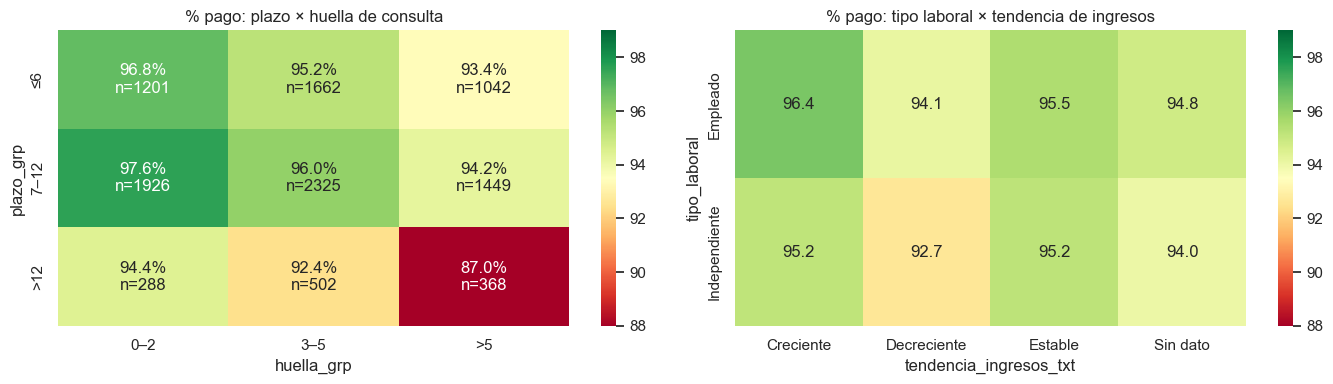

In [32]:
ct1 = pd.crosstab(d.tipo_laboral, d.tendencia_ingresos_txt, normalize="index").round(3)*100
display(ct1.rename_axis(None, axis=1).round(1))

d["plazo_grp"] = pd.cut(d.plazo_meses, [0, 6, 12, 100], labels=["≤6", "7–12", ">12"])
d["huella_grp"] = pd.cut(d.huella_consulta, [-1, 2, 5, 100], labels=["0–2", "3–5", ">5"])
heat = d.pivot_table(index="plazo_grp", columns="huella_grp", values=TARGET, aggfunc="mean", observed=True)*100
cnt  = d.pivot_table(index="plazo_grp", columns="huella_grp", values=TARGET, aggfunc="count", observed=True)

heat2 = d.pivot_table(index="tipo_laboral", columns="tendencia_ingresos_txt", values=TARGET, aggfunc="mean", observed=True)*100
cnt2  = d.pivot_table(index="tipo_laboral", columns="tendencia_ingresos_txt", values=TARGET, aggfunc="count", observed=True)
print("% pago: plazo × huella"); display(heat.round(1)); print("n:"); display(cnt)
print("% pago: tipo_laboral × tendencia"); display(heat2.round(1)); print("n:"); display(cnt2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(heat, annot=(heat.round(1).astype(str) + "%\nn=" + cnt.astype(str)), fmt="", cmap="RdYlGn", vmin=88, vmax=99, ax=axes[0])
axes[0].set_title("% pago: plazo × huella de consulta")
sns.heatmap(heat2, annot=True, fmt=".1f", cmap="RdYlGn", vmin=88, vmax=99, ax=axes[1])
axes[1].set_title("% pago: tipo laboral × tendencia de ingresos")
plt.tight_layout(); plt.show()

- **Plazo × huella:** el mejor segmento es plazo 7–12 con 0–2 consultas (**97,6 %**) y el peor, plazo > 12 con más de 5 consultas (**87,0 %**, n = 368). Los efectos se **acumulan**: conviene incluir interacciones o usar árboles/GBM.
- **Tendencia por tipo laboral:** el 41,5 % de los independientes no tiene dato (vs 19,7 % de los empleados) y solo el 36 % es "Creciente" (vs 57 %): tienen **mucha menos información en el buró**.
- Menor tasa: **independientes con tendencia decreciente** (92,7 %, n = 354). Mayor: **empleados con tendencia creciente** (96,4 %, n = 3.843).

## 5.5 Consistencia interna entre variables

Se prueban relaciones lógicas **entre columnas**; cada una se mide como la proporción de filas que la cumple. Si cumple 100 %, es una regla válida; si cumple parcialmente, es un problema de definición que debe resolver negocio.

In [33]:
chk = pd.DataFrame({
    "saldo_total >= saldo_principal": (d.saldo_total >= d.saldo_principal)[d.saldo_total.notna() & d.saldo_principal.notna()].mean(),
    "saldo_mora <= saldo_total":      (d.saldo_mora <= d.saldo_total)[d.saldo_mora.notna() & d.saldo_total.notna()].mean(),
    "Σ créditos por sector == cant_creditosvigentes": ((d.creditos_sectorFinanciero + d.creditos_sectorCooperativo + d.creditos_sectorReal) == d.cant_creditosvigentes).mean(),
    "Σ créditos por sector <= cant_creditosvigentes": ((d.creditos_sectorFinanciero + d.creditos_sectorCooperativo + d.creditos_sectorReal) <= d.cant_creditosvigentes).mean(),
    "cuota*plazo >= capital":         ((d.cuota_pactada*d.plazo_meses) >= d.capital_prestado).mean(),
}, index=["cumple (proporción)"]).T
display(chk)

dif = (d.creditos_sectorFinanciero + d.creditos_sectorCooperativo + d.creditos_sectorReal) - d.cant_creditosvigentes
print("Diferencia (Σ sectores − vigentes):"); print(dif.describe().round(2).to_string())
ratio = d.cuota_pactada*d.plazo_meses/d.capital_prestado
print("\ncuota*plazo / capital:"); print(ratio.describe().round(3).to_string())

,cumple (proporción)
saldo_total >= saldo_principal,1.0000
saldo_mora <= saldo_total,1.0000
Σ créditos por sector == cant_creditosvigentes,0.2896
Σ créditos por sector <= cant_creditosvigentes,0.9996
cuota*plazo >= capital,0.0910


Diferencia (Σ sectores − vigentes):
count   10,763.0000
mean        -1.3700
std          1.3100
min        -12.0000
25%         -2.0000
50%         -1.0000
75%          0.0000
max          2.0000

cuota*plazo / capital:
count   10,763.0000
mean         0.9120
std          0.0890
min          0.7880
25%          0.8500
50%          0.8940
75%          0.9420
max          1.5240


**Hallazgos de consistencia**
- `saldo_total ≥ saldo_principal` y `saldo_mora ≤ saldo_total` **se cumplen siempre** → reglas válidas.
- **Σ créditos por sector ≠ créditos vigentes en el 71 % de los casos**, pero casi siempre la suma por sector es **menor o igual** (99,96 %; diferencia mediana –1): `cant_creditosvigentes` incluye créditos fuera de los tres sectores (u otra fecha de corte). No sirve una regla de igualdad; sí **Σ sectores ≤ vigentes** (4 excepciones a revisar).
- **`cuota × plazo` es menor que el capital en el 91 % de los registros** (mediana del cociente 0,89). Con intereses debería ser mayor: quizá el capital incluya conceptos financiados (comisiones, seguros, IVA). **Pregunta crítica para negocio**; hasta entonces no se puede derivar una "tasa implícita".

# 6. Transformaciones sugeridas y atributos derivados
## 6.1 Transformaciones recomendadas

| Variable(s) | Problema | Transformación |
|---|---|---|
| `capital_prestado`, `cuota_pactada`, `salario_cliente` | Log-normales | `log1p` (modelos lineales/redes; innecesario en árboles) |
| `total_otros_prestamos`, `promedio_ingresos_datacredito`, saldos | Colas muy pesadas | `log1p` + winsorización p1–p99 (ajustada **solo con train**) |
| `total_otros_prestamos` | 44 valores > 100 M sin tratar | Mismo criterio que el salario (anular e imputar) o winsorizar |
| `saldo_mora` | ~99,5 % de ceros | `tiene_mora` (binaria) + monto en log |
| `tipo_credito` | Nominal; 3 niveles casi vacíos | Agrupar 6, 7, 68 como "Otros"; *one-hot* o *target encoding* regularizado |
| `tendencia_ingresos` | Ordinal con 27,8 % de nulos | Categoría "Sin dato" (o `sin_historial_ingresos_buro`); ordinal 0/1/2 para los observados |
| `plazo_meses` | Multimodal, efecto umbral | Numérica y/o tramos (≤ 6, 7–12, > 12) |
| `puntaje_datacredito`, `edad_cliente`, `huella_consulta` | Relación monótona (edad con umbral) | *Binning* (WoE/IV) para scorecard |
| Variables con nulos | Nulos informativos (salvo edad y salario, ya imputados) | Árboles (LightGBM/XGBoost/`HistGradientBoosting`): dejar el `NaN`. Modelos lineales/redes: imputar **dentro del pipeline y solo con train** (mediana + indicador `sin_*`) |
| Target | 95 / 5 | Partición **estratificada y temporal**; ponderación de clases o SMOTE solo en train |

`puntaje` ya fue eliminada en 4.4.

## 6.2 Atributos derivados (calculados)
Se construyen razones de **capacidad de pago y endeudamiento**, indicadores de **calidad de la información** y variables **temporales**, y se mide el poder (AUC univariable) de cada una:
- **Razones** en vez de montos absolutos: capturan la capacidad de pago relativa y eliminan el efecto de escala.
- `ratio_salario_vs_buro` y `cuota_sobre_ingreso_buro` solo existen para los clientes con historial en el buró (27 % de nulos).
- `huella_por_credito`: consultas normalizadas por créditos vigentes.
- Los denominadores en 0 pasan a `NaN` para evitar infinitos.

Se probaron otras (p. ej. `cuota × plazo / capital`, `saldo_total − saldo_principal`, `saldo_principal / saldo_total`) y se descartaron por no aportar señal (poder ≤ 0,02).

In [34]:
f = d.copy()
sal = f.salario_cliente.astype(float)
pib = f.promedio_ingresos_datacredito.replace(0, np.nan)   # NaN = sin historial en el buró
sc = f.saldo_total.replace(0, np.nan)
nc = f.creditos_sectorFinanciero + f.creditos_sectorCooperativo + f.creditos_sectorReal

# Capacidad de pago y endeudamiento
f["cuota_sobre_salario"]           = f.cuota_pactada / sal
f["capital_sobre_salario"]         = f.capital_prestado / sal
f["otros_prestamos_sobre_salario"] = f.total_otros_prestamos / sal
f["cuota_sobre_ingreso_buro"]      = f.cuota_pactada / pib
f["ratio_salario_vs_buro"]         = sal / pib                   # consistencia declarado vs buró
# Estructura de la deuda y comportamiento crediticio
f["ratio_mora_sobre_saldo"]        = f.saldo_mora / sc
f["saldo_total_sobre_capital"]     = f.saldo_total / f.capital_prestado
f["tiene_mora"]                    = (f.saldo_mora > 0).astype(float).where(f.saldo_mora.notna())
f["total_creditos_sectores"]       = nc
f["pct_sector_financiero"]         = f.creditos_sectorFinanciero / nc.replace(0, np.nan)
f["huella_por_credito"]            = f.huella_consulta / (f.cant_creditosvigentes + 1)
f["intensidad_busqueda"]           = f.huella_consulta / f.plazo_meses
f["plazo_largo"]                   = (f.plazo_meses > 12).astype(int)
# Temporales
f["dia_semana"]                    = f.fecha_prestamo.dt.dayofweek
f["hora_desembolso"]               = f.fecha_prestamo.dt.hour
f["es_fin_de_semana"]              = (f.dia_semana >= 5).astype(int)
f["dias_desde_inicio"]             = (f.fecha_prestamo - f.fecha_prestamo.min()).dt.days

derivadas = ["cuota_sobre_salario", "capital_sobre_salario", "otros_prestamos_sobre_salario", "cuota_sobre_ingreso_buro",
             "ratio_salario_vs_buro", "ratio_mora_sobre_saldo", "saldo_total_sobre_capital", "tiene_mora",
             "total_creditos_sectores", "pct_sector_financiero", "huella_por_credito", "intensidad_busqueda",
             "plazo_largo", "dia_semana", "hora_desembolso", "es_fin_de_semana", "dias_desde_inicio"]
f[derivadas] = f[derivadas].astype(float).replace([np.inf, -np.inf], np.nan)

res = pd.DataFrame({c: {"%nulos": f[c].isna().mean()*100, "mediana": f[c].median(), "AUC": auc_uni(f[c], f[TARGET])}
                    for c in derivadas}).T
res["poder"] = (res.AUC - .5).abs() * 2
res = res.sort_values("poder", ascending=False)
with pd.option_context("display.float_format", lambda x: f"{x:,.4f}"): display(res)

,%nulos,mediana,AUC,poder
huella_por_credito,0.0000,0.6000,0.3962,0.2076
ratio_salario_vs_buro,27.2879,1.8095,0.4305,0.1391
cuota_sobre_ingreso_buro,27.2879,0.1283,0.4394,0.1211
dias_desde_inicio,0.0000,121.0000,0.5516,0.1032
intensidad_busqueda,0.0000,0.3750,0.4486,0.1027
plazo_largo,0.0000,0.0000,0.4517,0.0966
es_fin_de_semana,0.0000,0.0000,0.4520,0.0960
dia_semana,0.0000,3.0000,0.4535,0.0930
otros_prestamos_sobre_salario,0.0000,0.3378,0.5443,0.0885
capital_sobre_salario,0.0000,0.6408,0.4591,0.0819


Se compara el poder de las mejores derivadas con el de las mejores originales, para saber si la ingeniería de variables aportó algo.

In [35]:
orig = biv_num.drop(index="puntaje")["poder (|AUC-.5|*2)"].head(5)
print("Poder de las 5 mejores variables ORIGINALES (sin 'puntaje'):"); print(orig.round(3).to_string())
print("\nPoder de las 8 mejores DERIVADAS:"); print(res.poder.head(8).round(3).to_string())

Poder de las 5 mejores variables ORIGINALES (sin 'puntaje'):
variable
puntaje_datacredito             0.2480
huella_consulta                 0.1960
edad_cliente                    0.1470
promedio_ingresos_datacredito   0.1450
capital_prestado                0.1140

Poder de las 8 mejores DERIVADAS:
huella_por_credito         0.2080
ratio_salario_vs_buro      0.1390
cuota_sobre_ingreso_buro   0.1210
dias_desde_inicio          0.1030
intensidad_busqueda        0.1030
plazo_largo                0.0970
es_fin_de_semana           0.0960
dia_semana                 0.0930


**Qué muestran los derivados**
- **Ninguna supera a la mejor original** (`puntaje_datacredito`, 0,24), pero **`huella_por_credito` (0,21)** se acerca y mejora ligeramente a `huella_consulta` (0,20).
- **Declarado vs buró:** `ratio_salario_vs_buro` (0,14) y `cuota_sobre_ingreso_buro` (0,12) son informativas: la tasa de pago baja de ≈ 97 % (salario similar al ingreso del buró) a ≈ 94 % (cuando lo supera ampliamente). Señal de **sobredeclaración** o de ingresos no formales.
- **Contraste:** las razones con el **salario declarado** son débiles (`cuota_sobre_salario` 0,02; `capital_sobre_salario` 0,08) y las del buró no: el salario declarado es poco confiable.
- **Temporales:** `dias_desde_inicio` (0,10) refleja la deriva temporal (3.4 y 4.6): útil para diagnóstico, **peligrosa como predictor**. `es_fin_de_semana` (0,10): fin de semana paga 93,7 % vs 95,9 % en días hábiles (p < 0,001), y antes de las 8 h, 93,3 %. **No es causal**: puede ser un proxy del canal o del producto (el tipo 9 pesa más en fines de semana: 32,8 % vs 24,3 %). Investigar el canal antes de usarla.

Se grafican las tres derivadas más informativas para comprobar que la relación sea interpretable y no un artefacto del AUC.


huella_por_credito:
huella_por_credito  (-0.001, 0.2]  (0.2, 0.333]  (0.333, 0.5]  (0.5, 0.6]  (0.6, 0.75]  (0.75, 1.0]  (1.0, 1.4]  (1.4, 3.5]
%pago                     96.7000       97.3000       96.5000     94.9000      95.3000      94.8000     93.1000     91.6000
count                  1,392.0000    1,432.0000    2,035.0000    690.0000   1,307.0000   1,771.0000    810.0000  1,326.0000

ratio_salario_vs_buro:
ratio_salario_vs_buro  (0.0515, 0.937]  (0.937, 1.081]  (1.081, 1.35]  (1.35, 1.809]  (1.809, 2.503]  (2.503, 3.595]  (3.595, 5.524]  (5.524, 99.059]
%pago                          97.0000         96.7000        96.8000        95.5000         94.1000         96.2000         94.6000          94.0000
count                         979.0000        978.0000       978.0000       978.0000        978.0000        978.0000        978.0000         979.0000

cuota_sobre_ingreso_buro:
cuota_sobre_ingreso_buro  (0.0015600000000000002, 0.0443]  (0.0443, 0.0689]  (0.0689, 0.096]  (0.096, 0.12

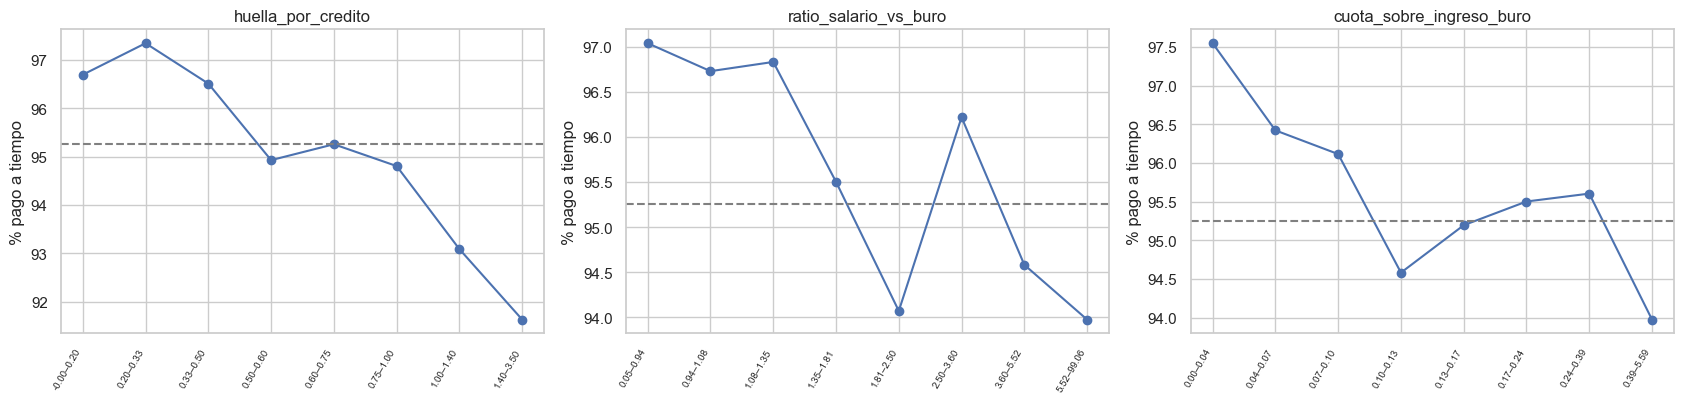


Tasa de pago por día de la semana / fin de semana / franja horaria:


dia_semana,0.0000,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000
tasa_pago,95.0300,96.6700,96.4900,95.2100,96.0900,93.7700,93.7200
n,"1,307.0000","1,412.0000","1,254.0000","1,899.0000","1,789.0000","1,621.0000","1,481.0000"


,tasa_pago,n
es_fin_de_semana,,
0.0000,95.8600,7661
1.0000,93.7500,3102


Chi² fin de semana vs pago: p = 3.73e-06

Mezcla de tipo_credito según fin de semana (¿posible confusor?):


tipo_credito_grp,10,4,9,Otros
es_fin_de_semana,,,,
0.0000,1.1000,74.4000,24.3000,0.2000
1.0000,1.0000,65.9000,32.8000,0.3000


hora_desembolso,"(-1, 8]","(8, 12]","(12, 16]","(16, 20]","(20, 24]"
tasa_pago,93.3000,94.6200,95.9600,95.2600,NaN
n,433.0000,"3,641.0000","4,411.0000","2,278.0000",0.0000


In [36]:
# Tasa de pago por tramos de los derivados más discriminantes
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, v in zip(axes, ["huella_por_credito", "ratio_salario_vs_buro", "cuota_sobre_ingreso_buro"]):
    x = f[v].clip(upper=f[v].quantile(.99))
    t = f.groupby(pd.qcut(x, 8, duplicates="drop"), observed=True)[TARGET].agg(["mean", "count"])
    ax.plot(range(len(t)), t["mean"]*100, marker="o"); ax.axhline(f[TARGET].mean()*100, color="gray", ls="--")
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{i.left:.2f}–{i.right:.2f}" for i in t.index], rotation=60, ha="right", fontsize=7)
    ax.set_title(v); ax.set_ylabel("% pago a tiempo")
    print(f"\n{v}:"); print(t.assign(mean=t["mean"]*100).rename(columns={"mean": "%pago"}).round(1).T.to_string())
plt.tight_layout(); plt.show()

print("\nTasa de pago por día de la semana / fin de semana / franja horaria:")
display(f.groupby("dia_semana")[TARGET].agg(tasa_pago="mean", n="count").assign(tasa_pago=lambda x: x.tasa_pago*100).round(2).T)
display(f.groupby("es_fin_de_semana")[TARGET].agg(tasa_pago="mean", n="count").assign(tasa_pago=lambda x: x.tasa_pago*100).round(2))
print("Chi² fin de semana vs pago: p =", f"{stats.chi2_contingency(pd.crosstab(f.es_fin_de_semana, f[TARGET]))[1]:.2e}")
print("\nMezcla de tipo_credito según fin de semana (¿posible confusor?):")
display(pd.crosstab(f.es_fin_de_semana, f.tipo_credito_grp, normalize="index").mul(100).round(1))
display(f.groupby(pd.cut(f.hora_desembolso, [-1, 8, 12, 16, 20, 24]))[TARGET].agg(tasa_pago="mean", n="count").assign(tasa_pago=lambda x: x.tasa_pago*100).round(2).T)

Las curvas son **interpretables**: más consultas por crédito vigente (97 % → 91,6 %), mayor desfase entre salario declarado e ingreso del buró (97,0 % → 94,0 %, con algo de ruido) y mayor cuota sobre el ingreso del buró (97,5 % → 94,0 %) se asocian a menor pago.

# 7. Conjunto de datos limpio y resumen de hallazgos
## 7.1 Exportación
Se guarda el dataset limpio (sin `puntaje`, con los atributos derivados). Solo se excluyen las columnas auxiliares creadas para los gráficos. `dias_desde_inicio` queda para diagnóstico, pero **no se recomienda usarla como predictora** (deriva temporal).

In [37]:
drop_model = ["tipo_credito_grp", "tendencia_ingresos_txt", "tipo_credito_txt", "plazo_grp", "huella_grp"]
base_cols = [c for c in d.columns if c not in drop_model]
df_modelo = f[list(dict.fromkeys(base_cols + derivadas))].copy()   # sin columnas repetidas
print("Dataset de modelado:", df_modelo.shape)
OUT = "/mnt/user-data/outputs" if os.path.isdir("/mnt/user-data/outputs") else "."
df_modelo.to_csv(f"{OUT}/Base_de_datos_limpia.csv", index=False)
print("Guardado en:", OUT)

Dataset de modelado: (10763, 42)
Guardado en: .


## 7.2 Conclusiones

**Calidad de los datos**
1. Base estructuralmente sana (sin duplicados ni nulos en el target o las variables de originación), con **problemas puntuales graves**: 58 valores numéricos en `tendencia_ingresos`, 150 edades centinela (121–123), 24 salarios en 0, 74 salarios > 100 M (hasta 22.000 M) y 146 scores de buró ≤ 0. Además, 44 valores de `total_otros_prestamos` > 100 M siguen sin tratar.
2. **27 % de nulos en los ingresos del buró:** es un nulo **informativo** (clientes sin historial, mucho más frecuentes entre independientes) → se conserva un indicador.
3. **Criterio de imputación según la definición de cada variable:** solo se imputaron `edad_cliente` y `salario_cliente` (el dato existe pero no se capturó). Los nulos de ingresos y tendencia del buró y del score significan "sin historial" o "sin calificación", y los de los saldos están por definir con negocio: se dejaron en `NaN`, con indicadores `sin_*`.
4. `saldo_mora_codeudor` es casi constante (99,97 % en un valor): no se elimina; su uso se decide en la selección de variables.

**Hallazgos sobre el problema**
5. **`puntaje` es fuga de información** (AUC = 1,00, sin solapamiento): se eliminó en 4.4; falta validarlo con negocio.
6. **Target desbalanceado (95,25 / 4,75):** métricas y particiones adecuadas (AUC-PR, KS, recall de la clase 0, estratificación).
7. Sin `puntaje`, el poder de cada variable es **modesto**. Las señales más claras: `puntaje_datacredito`, `huella_consulta` (y por crédito vigente), edad, ingreso del buró, **plazo > 12 meses**, monto alto, mora vigente (pocos casos) y el desfase entre ingreso declarado y del buró. Se **acumulan** (plazo largo + muchas consultas → 87 % de pago).
8. **El salario declarado es poco confiable** (errores de escala, sin poder predictivo): mejor usar el ingreso del buró.
9. **Los fines de semana** pagan menos (93,7 % vs 95,9 %): investigar canal o producto antes de usarla.
10. **Sesgo temporal:** el volumen baja de ≈ 1.900 créditos/mes (enero 2025) a menos de 100 (desde febrero 2026) y la tasa de pago mejora de forma sospechosa en los trimestres recientes → validación temporal y definir la ventana de observación del target.
